# Kelvin OLR variance and spectral excess in wavenumber–frequency space

**Agent-authored exploratory analysis.** One NOAA record and 59 CMIP6 Historical/AMIP model records over 1990–2010. Each record has its own single-panel map. Figures are embedded here; no standalone figures are saved.

**Questions.** Where in fitted Kelvin $K$–$f$ space do detected events contribute OLR variance? How does that event-assigned map compare with ordinary Fourier OLR variance and with the background-normalized Wheeler–Kiladis-style signal?

## Three distinct variance maps

1. **Event-footprint variance, assigned to fitted coordinates.** For each quality-screened Kelvin event, the variance contribution is the sum of squared filtered OLR anomalies on its active component, divided by the number of time–longitude samples. We assign that contribution to the event's fitted $K,f$ bin. The color shows its percentage of the total symmetric-plus-antisymmetric projected OLR anomaly variance. Active supports are disjoint, but their variance includes background fluctuations on those pixels; it is not uniquely attributable to a coherent Kelvin carrier. The screen is `keep_for_histogram`, not the separate 1% amplitude-significance test.
2. **Raw 96-day segment spectral variance.** This is symmetric projected OLR Fourier variance, averaged over overlapping 96-day windows and summed into the same $K,f$ bins. It uses all OLR in the record, regardless of detected events. The color scale is logarithmic because the broad OLR spectrum is red.
3. **WK-style spectral excess.** The ratio of the symmetric segment variance to the smoothed, pooled symmetric/antisymmetric background variance in each bin. Values above one show power in excess of that background. Dashed and dotted curves mark resting Kelvin dispersion for 12 and 50 m equivalent depth. This reproduces the *kind* of diagnostic in [Wheeler and Kiladis (1999)](https://wind.mit.edu/~emanuel/tropical/wheeler_kiladis_1999.pdf), with this project's daily OLR, meridional-mean projection, 96-day segments, and documented smoothing choices; it is not a reproduction of their data or exact estimator.

All maps use common bins: global zonal wavenumber bins centered on integer $K=1$–15 (edges 0.5–15.5) and frequency $f=0.07$–0.41 cycles/day in steps of 0.02. Top/right axes show dimensional $k=K/R$ and $\omega=2\pi f/86400$, where $R=6{,}371{,}008$ m. Each map type uses one color scale across all 60 records.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, Normalize, TwoSlopeNorm
import numpy as np
import pandas as pd
from IPython.display import display

from src.paths import DATA_DIR

INPUT = DATA_DIR / "wave_significance/codex_kelvin_komega"
index = pd.read_csv(INPUT / "kelvin_catalog_index.csv")
paths = sorted((INPUT / "variance_bins_integer_centered").glob("*.csv.gz"))
if len(index) != 60 or len(paths) != 60:
    raise RuntimeError("Expected one NOAA and 59 model Kelvin variance-bin tables")
variance = pd.concat((pd.read_csv(path) for path in paths), ignore_index=True)
wk = pd.read_csv(INPUT / "wk_segment_bins_integer_centered.csv.gz")
IDENTITY = ["model", "experiment", "member"]
if (len(variance) != 60 * 2 * 15 * 17 or len(wk) != 60 * 15 * 17
        or variance.duplicated(IDENTITY + ["selection", "K_left", "f_lower_cpd"]).any()
        or wk.duplicated(IDENTITY + ["K_left", "f_lower_cpd"]).any()
        or set(map(tuple, variance[IDENTITY].drop_duplicates().to_numpy()))
           != set(map(tuple, index[IDENTITY].to_numpy()))
        or set(map(tuple, wk[IDENTITY].drop_duplicates().to_numpy()))
           != set(map(tuple, index[IDENTITY].to_numpy()))):
    raise RuntimeError("Incomplete or duplicated Kelvin variance maps")
records = pd.concat((index.loc[index.experiment.eq("observations")],
                     index.loc[index.experiment.eq("historical")].sort_values("model"),
                     index.loc[index.experiment.eq("amip")].sort_values("model")), ignore_index=True)
K_EDGES = np.arange(0.5, 16.0, 1.0)
F_EDGES = np.arange(0.07, 0.4101, 0.02)
EARTH_RADIUS_M = 6_371_008.0
GRAVITY_M_S2 = 9.80665
support_max = variance.loc[variance.selection.eq("screened"), "support_pct_projected"].max()
raw_min = wk.segment_variance_W2_m4.min()
raw_max = wk.segment_variance_W2_m4.max()
ratio_min = wk.segment_observed_to_background.min()
ratio_max = wk.segment_observed_to_background.max()
if (support_max <= 0 or raw_min <= 0 or not 0.2 < ratio_min < 1
        or not 1 < ratio_max < 2.5):
    raise RuntimeError("Inspect unexpected variance or WK-ratio color range")
print(f"Loaded 60 records; event maximum {support_max:.3f}% per bin; "
      f"segment variance {raw_min:.4g}–{raw_max:.3g} (W m-2)^2/bin; "
      f"WK-style ratio {ratio_min:.2f}–{ratio_max:.2f}")

Loaded 60 records; event maximum 0.844% per bin; segment variance 0.0008543–1.32 (W m-2)^2/bin; WK-style ratio 0.25–2.42


In [2]:
def plot_records(kind, experiment):
    """Display one Kelvin K–f variance or excess map for each requested record."""
    for row in records.loc[records.experiment.eq(experiment)].itertuples(index=False):
        identity = (row.model, row.experiment, row.member)
        if kind == "event":
            subset = variance.loc[(variance.model == identity[0])
                                  & (variance.experiment == identity[1])
                                  & (variance.member == identity[2])
                                  & variance.selection.eq("screened")]
            values = subset.sort_values(["K_left", "f_lower_cpd"]).support_pct_projected.to_numpy()
            z = np.ma.masked_equal(values.reshape(15, 17).T, 0)
            cmap = plt.get_cmap("magma").copy()
            cmap.set_bad("white")
            norm = Normalize(vmin=0, vmax=support_max)
            colorbar = "Percent of total projected OLR variance per bin"
            label = "screened event-footprint variance"
            count = f"; n={int(subset.selected_events.iloc[0])}"
        else:
            subset = wk.loc[(wk.model == identity[0])
                            & (wk.experiment == identity[1])
                            & (wk.member == identity[2])].sort_values(["K_left", "f_lower_cpd"])
            if kind == "raw":
                z = subset.segment_variance_W2_m4.to_numpy().reshape(15, 17).T
                cmap = "magma"
                norm = LogNorm(vmin=raw_min, vmax=raw_max)
                colorbar = r"96-day symmetric OLR variance [$(W\,m^{-2})^2$/bin]"
                label = "96-day segment OLR variance"
            elif kind == "excess":
                z = subset.segment_observed_to_background.to_numpy().reshape(15, 17).T
                cmap = "RdBu_r"
                norm = TwoSlopeNorm(vmin=0.2, vcenter=1, vmax=2.5)
                colorbar = "Symmetric segment power / smooth background"
                label = "WK-style spectral excess"
            else:
                raise ValueError(kind)
            count = ""
        if len(subset) != 15 * 17:
            raise RuntimeError(f"Incomplete {kind} map: {identity}")
        fig, ax = plt.subplots(figsize=(7.4, 4.9), dpi=85, layout="constrained")
        mesh = ax.pcolormesh(K_EDGES, F_EDGES, z, cmap=cmap, norm=norm, shading="flat")
        ax.set(xlim=(0.5, 15.5), ylim=(0.07, 0.41),
               xlabel="Global zonal wavenumber K (cycles/circumference)",
               ylabel="Frequency f (cycles/day)")
        ax.set_xticks(np.arange(1, 16, 2))
        ax.set_yticks([0.07, 0.1, 0.2, 0.3, 0.4])
        top = ax.secondary_xaxis("top", functions=(
            lambda K: K / EARTH_RADIUS_M * 1e6,
            lambda k_scaled: k_scaled * 1e-6 * EARTH_RADIUS_M))
        top.set_xlabel(r"$k$ ($10^{-6}$ rad m$^{-1}$)")
        right = ax.secondary_yaxis("right", functions=(
            lambda f: 2 * np.pi * f / 86400 * 1e5,
            lambda omega_scaled: omega_scaled * 1e-5 * 86400 / (2 * np.pi)))
        right.set_ylabel(r"$\omega$ ($10^{-5}$ rad s$^{-1}$)")
        if kind == "excess":
            K_curve = np.linspace(1, 15, 200)
            for depth, style in ((12, "--"), (50, ":")):
                f_curve = (np.sqrt(GRAVITY_M_S2 * depth) * K_curve
                           / EARTH_RADIUS_M * 86400 / (2 * np.pi))
                ax.plot(K_curve, f_curve, color="#202020", linestyle=style,
                        linewidth=0.9, label=f"Kelvin {depth} m")
            ax.legend(frameon=False, fontsize=7, loc="upper right")
        fig.colorbar(mesh, ax=ax, label=colorbar, pad=0.13)
        name = "NOAA OLR" if row.experiment == "observations" else f"{row.model} ({row.experiment}, {row.member})"
        fig.suptitle(f"{name} — {label}{count}", fontsize=8.5)
        display(fig)
        plt.close(fig)

## Event-footprint OLR variance by fitted Kelvin coordinates

Only quality-screened fitted events are shown; each active footprint contributes variance to one fitted K–f bin.

### NOAA observations

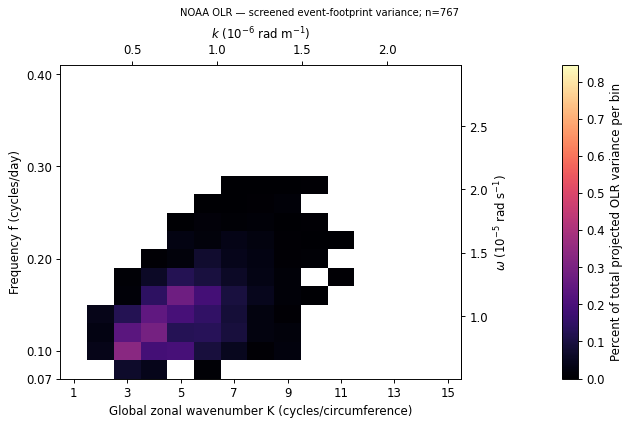

In [3]:
plot_records("event", "observations")

### Historical models (34 records)

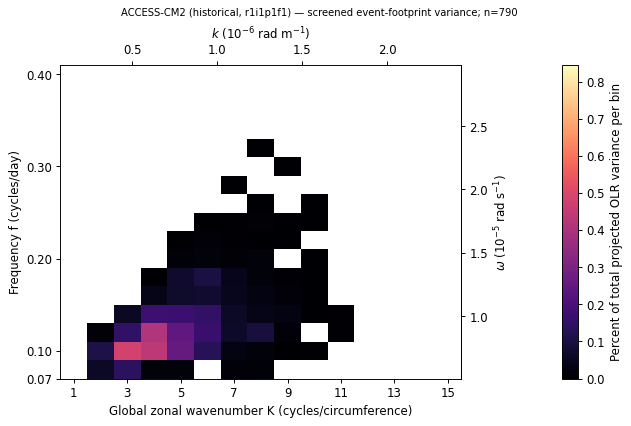

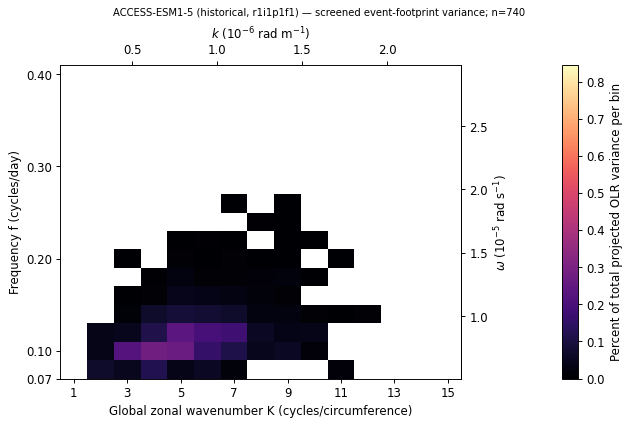

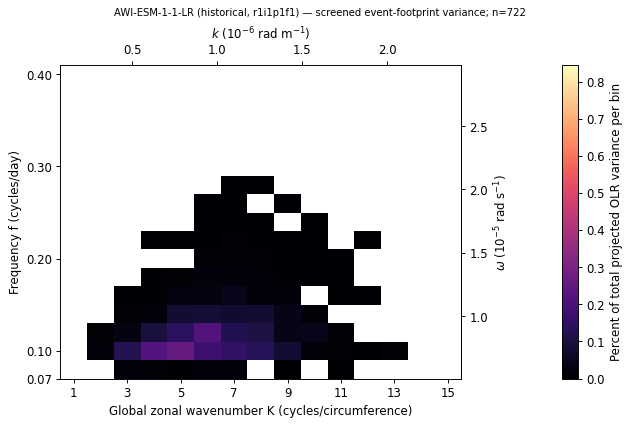

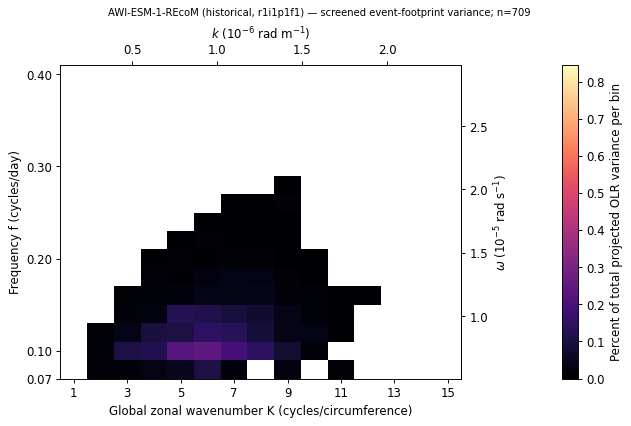

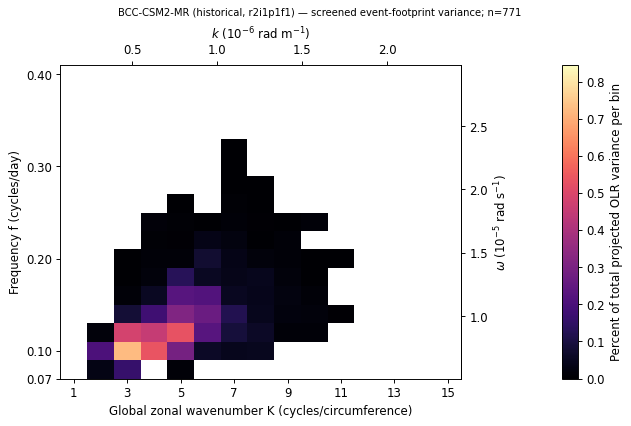

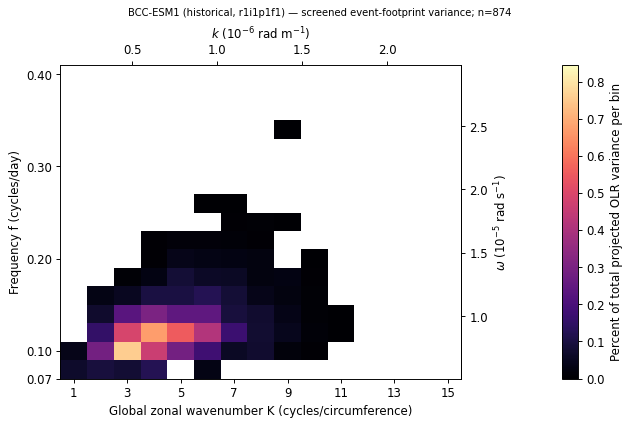

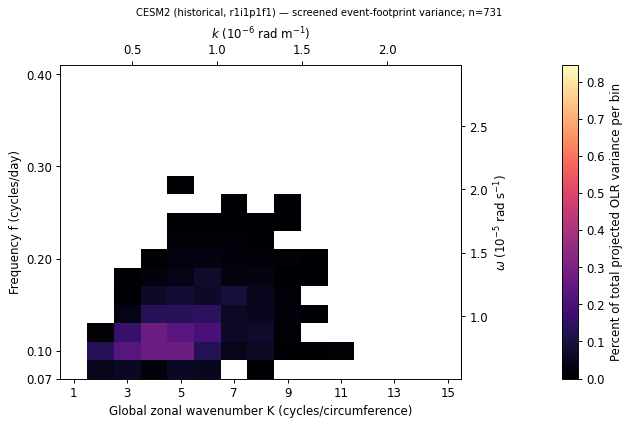

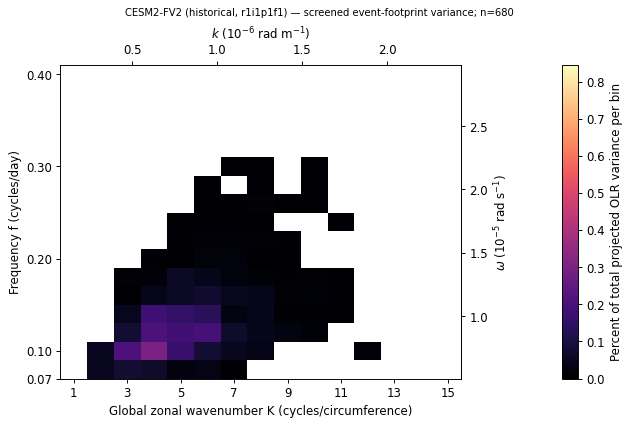

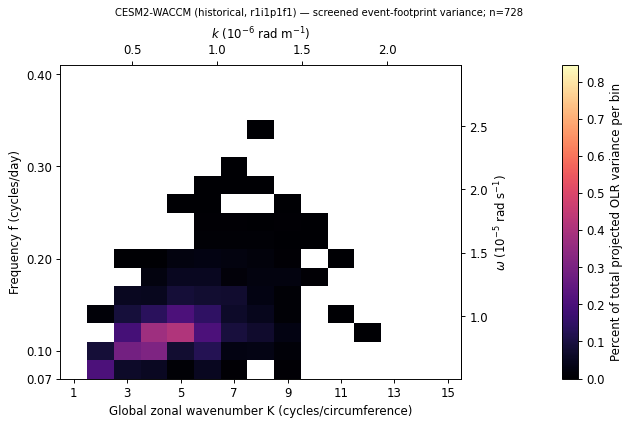

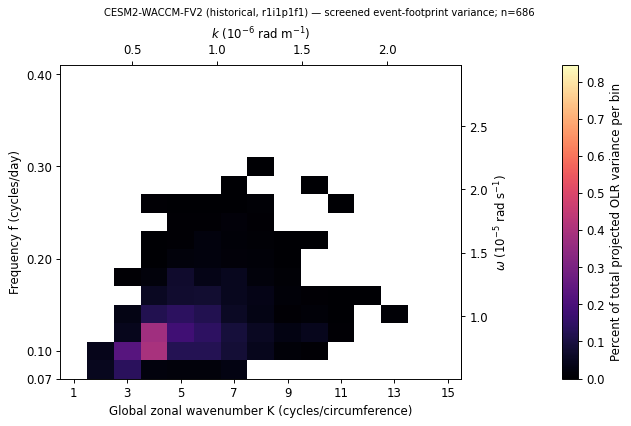

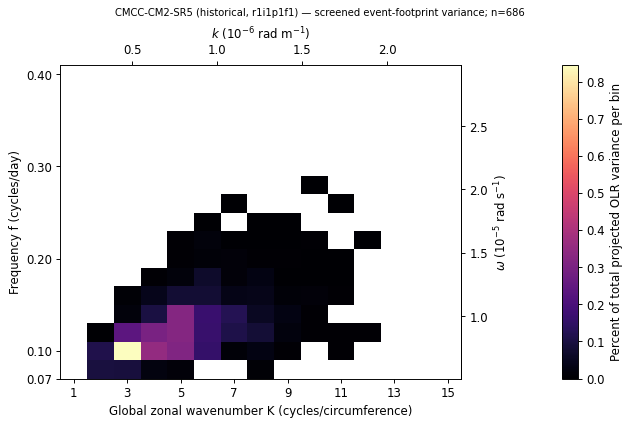

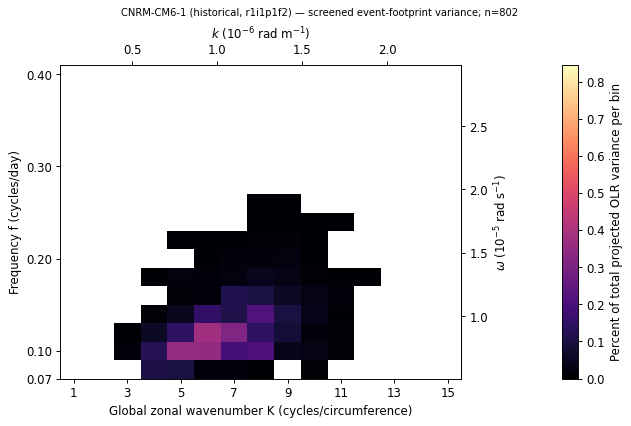

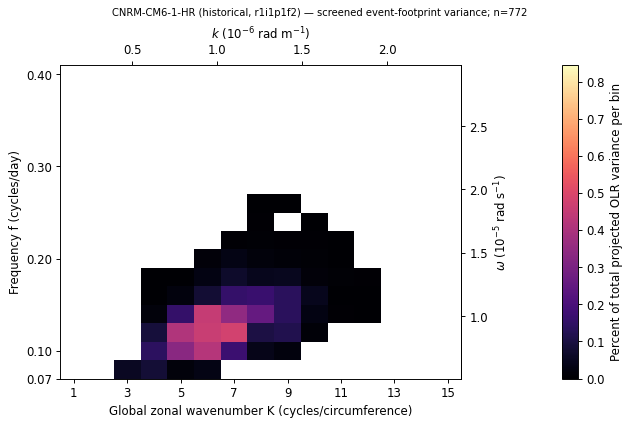

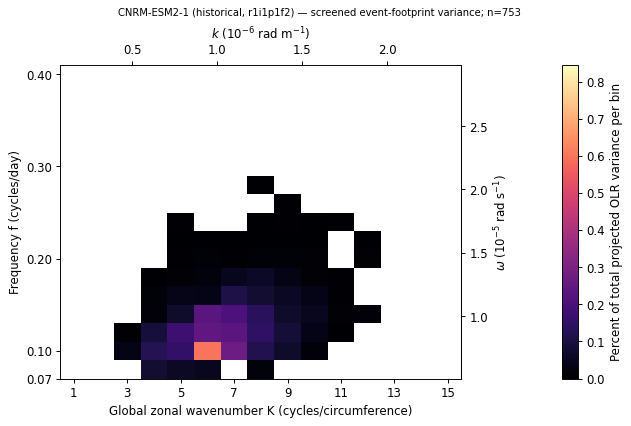

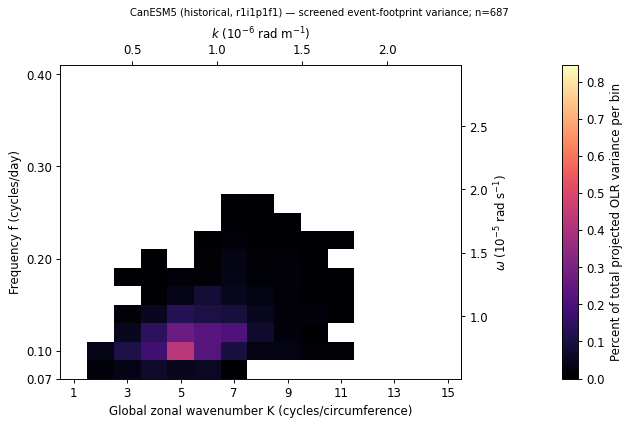

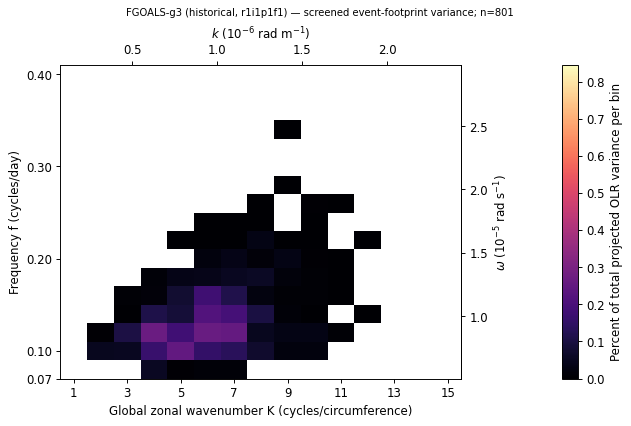

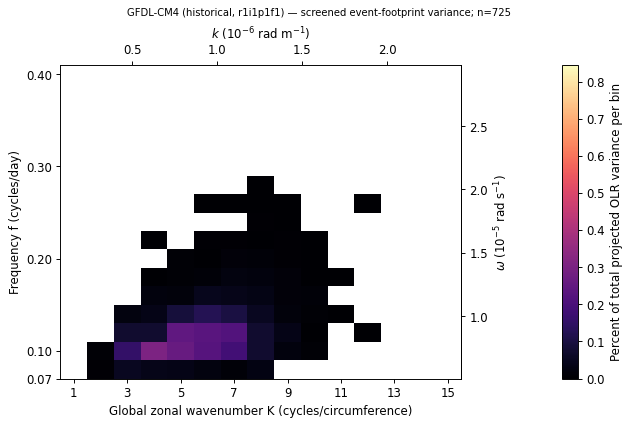

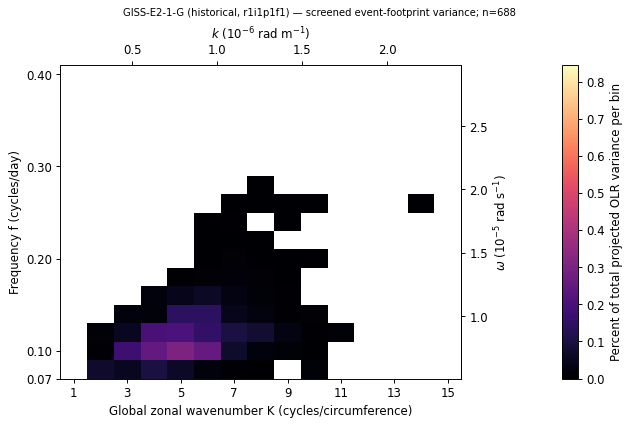

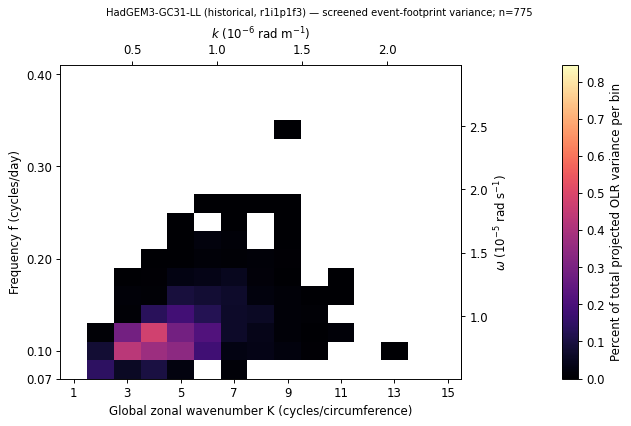

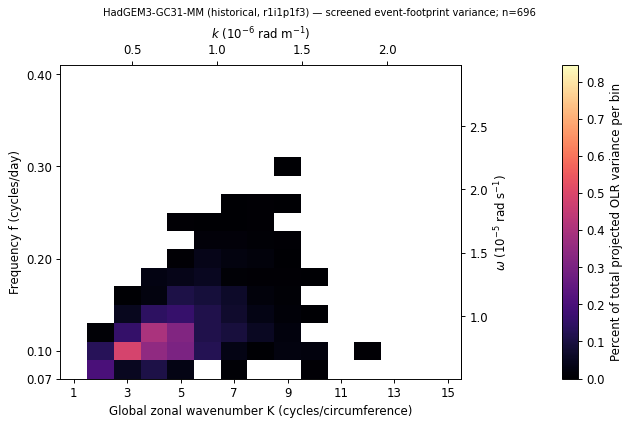

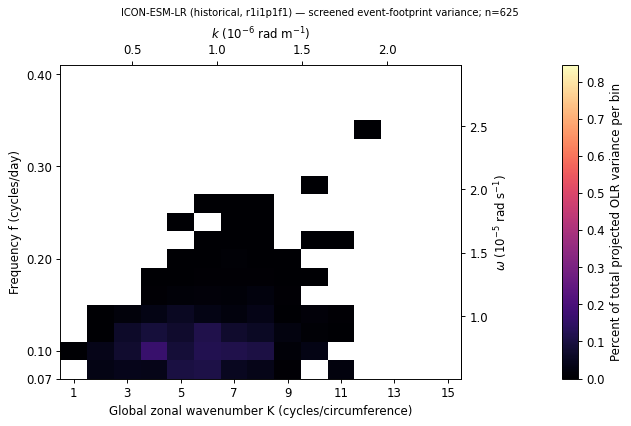

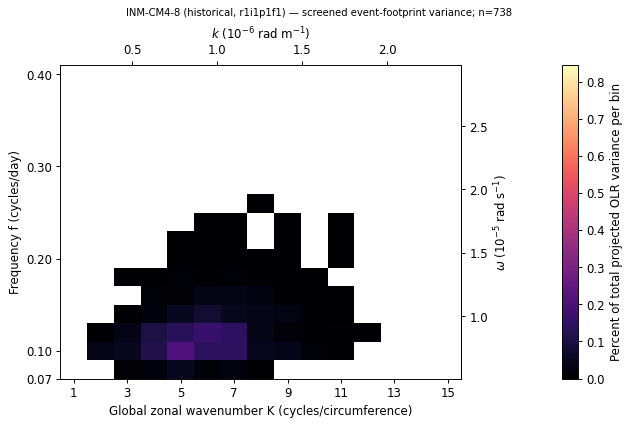

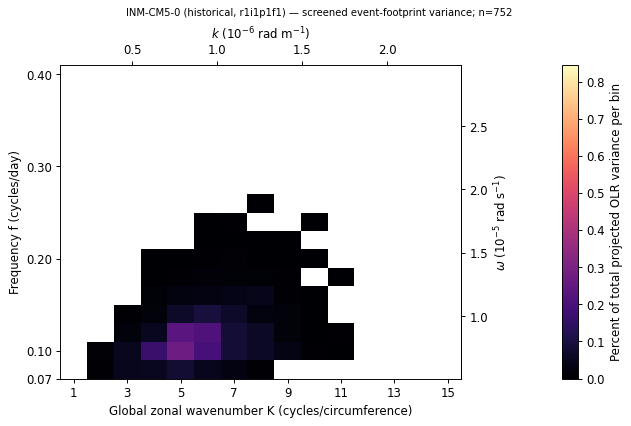

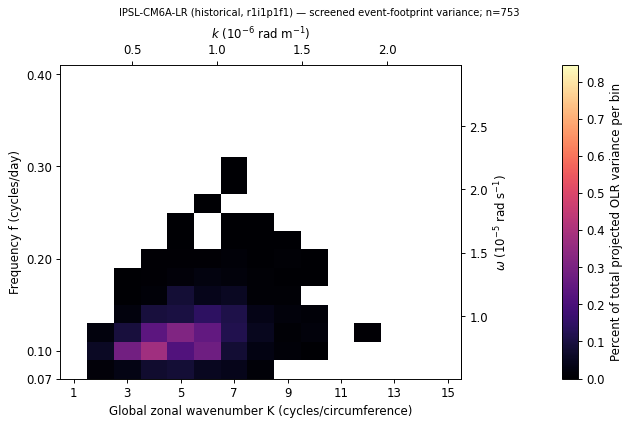

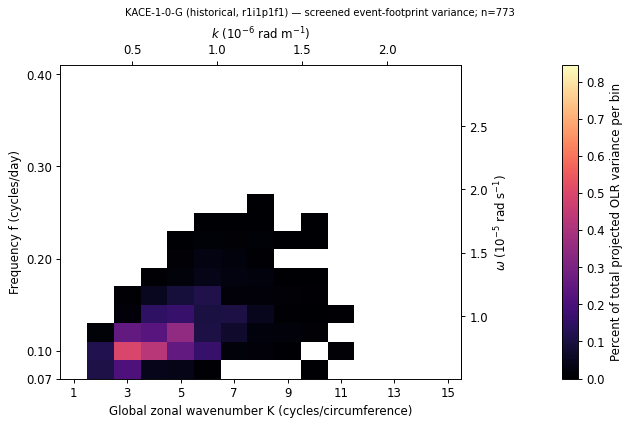

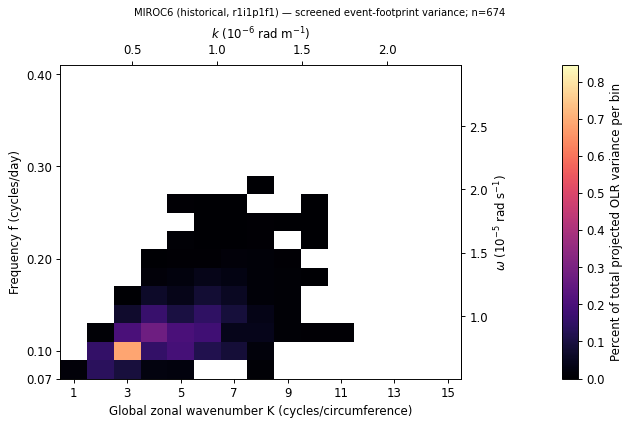

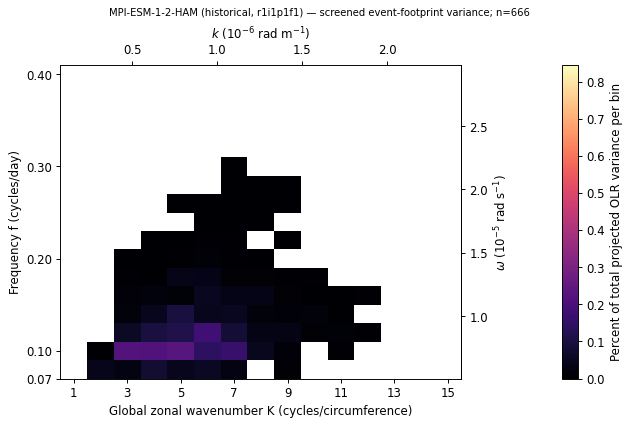

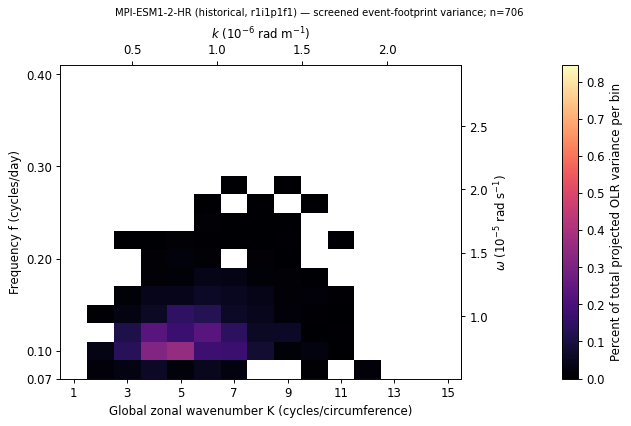

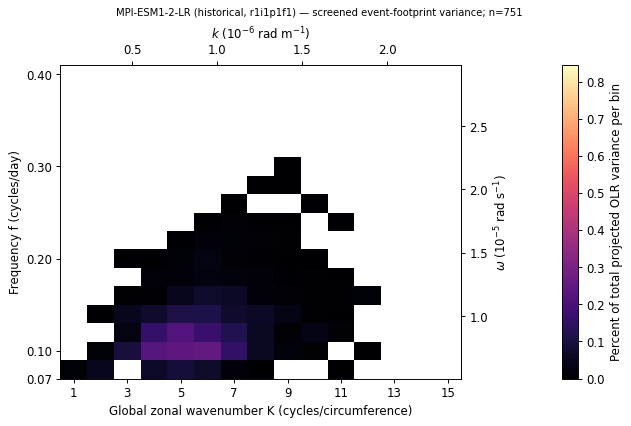

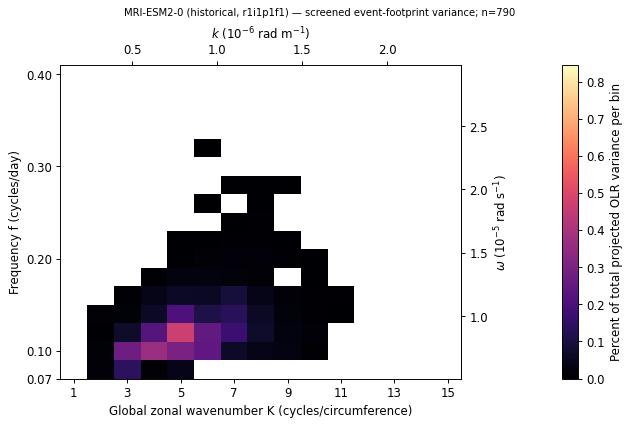

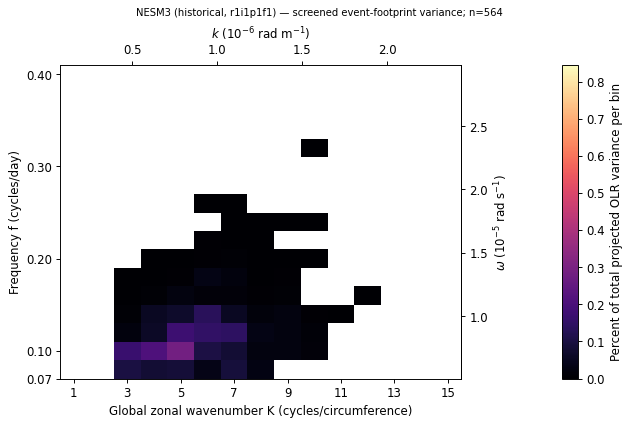

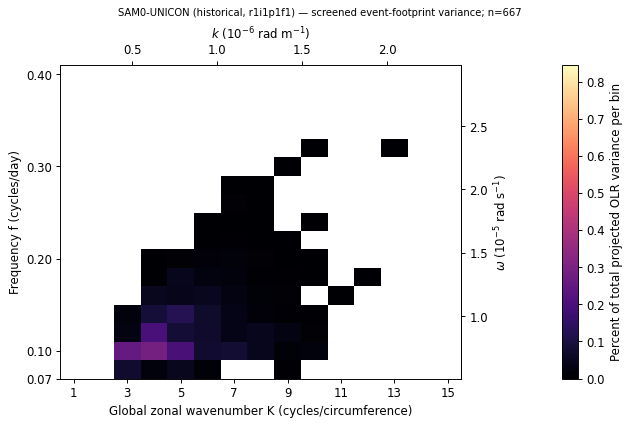

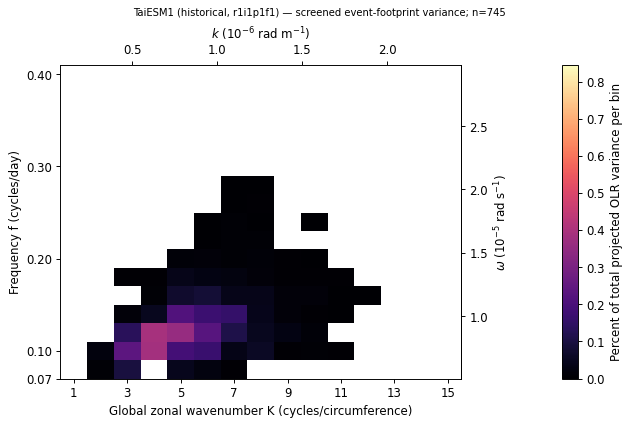

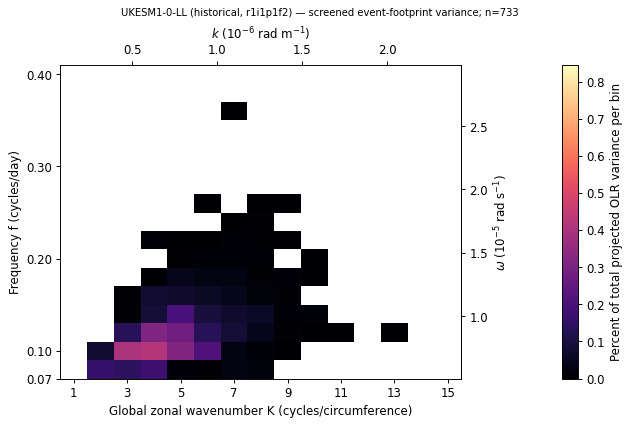

In [4]:
plot_records("event", "historical")

### AMIP models (25 records)

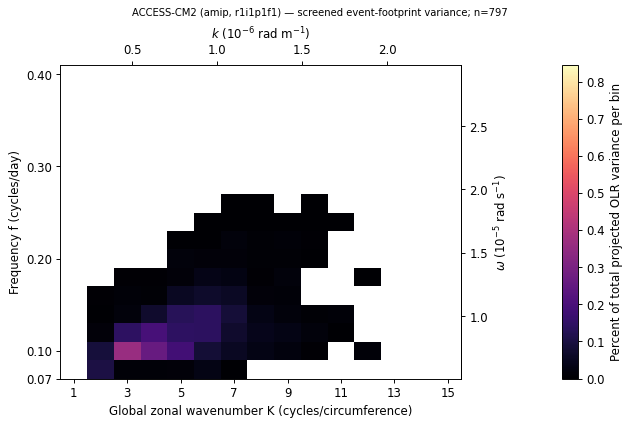

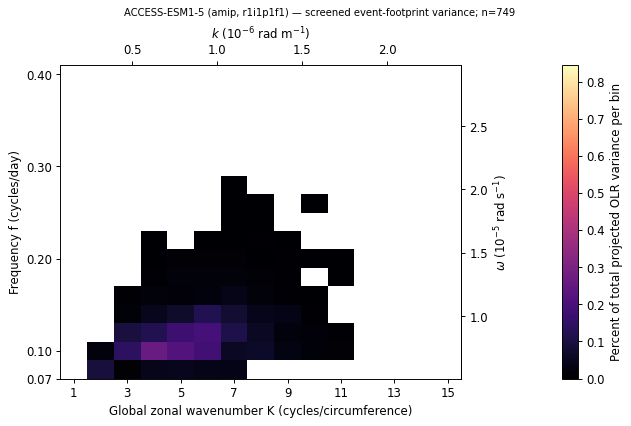

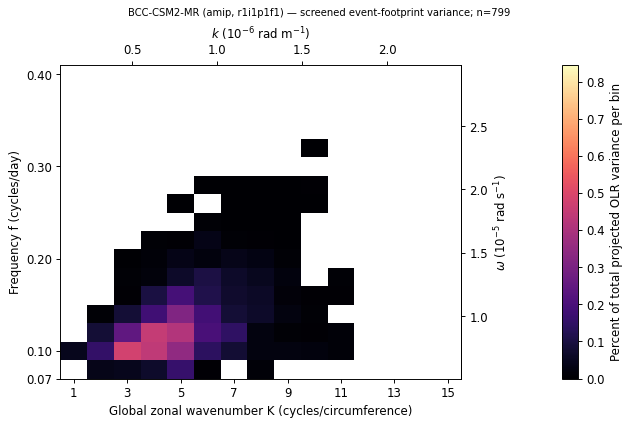

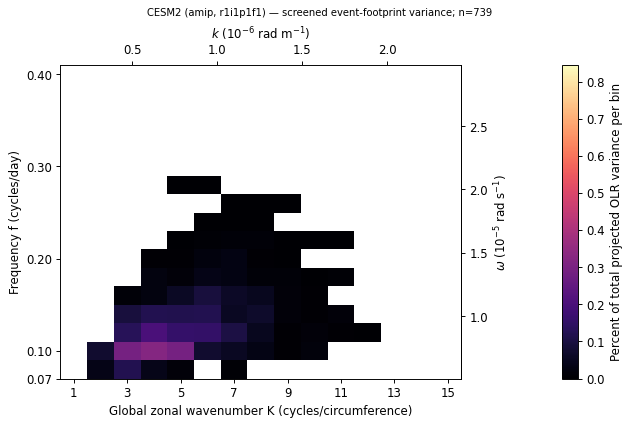

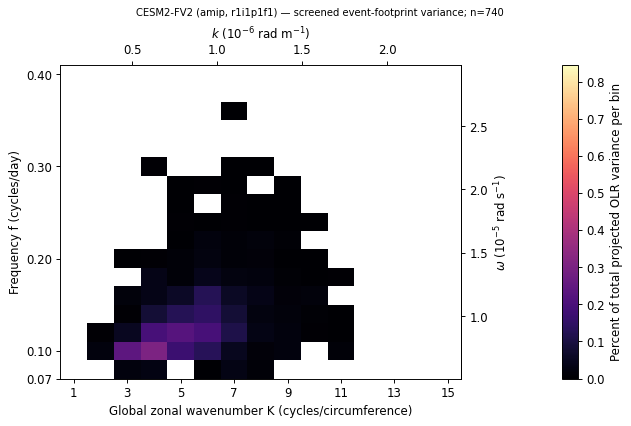

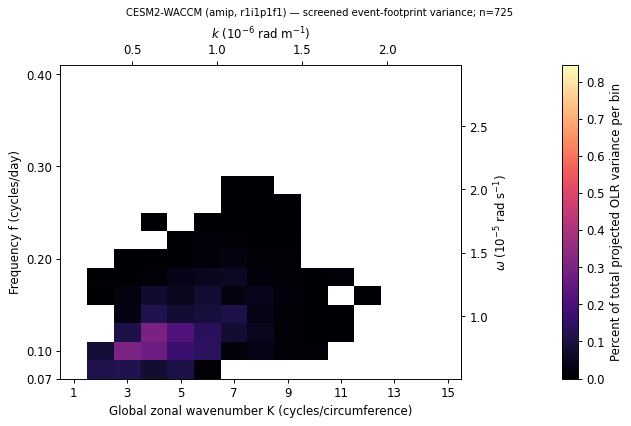

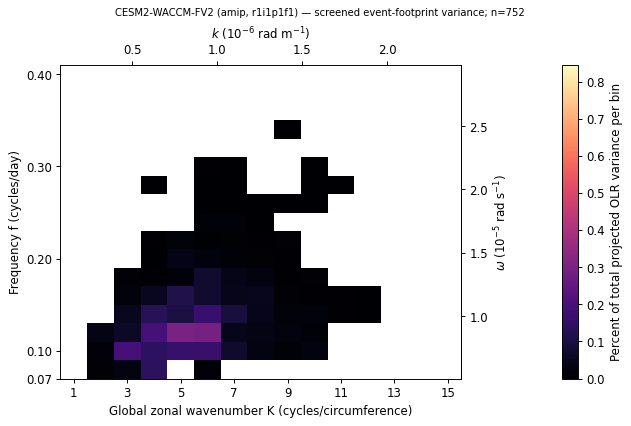

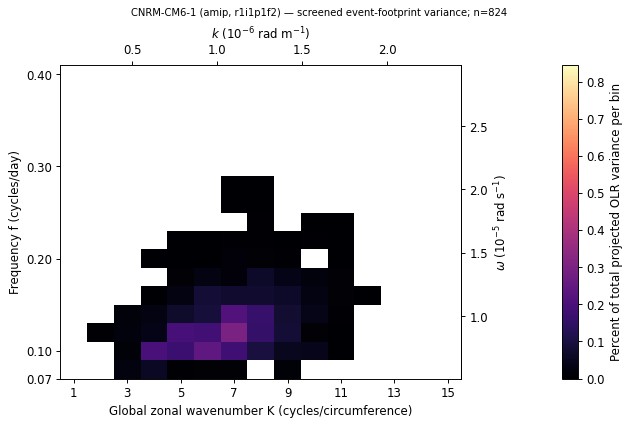

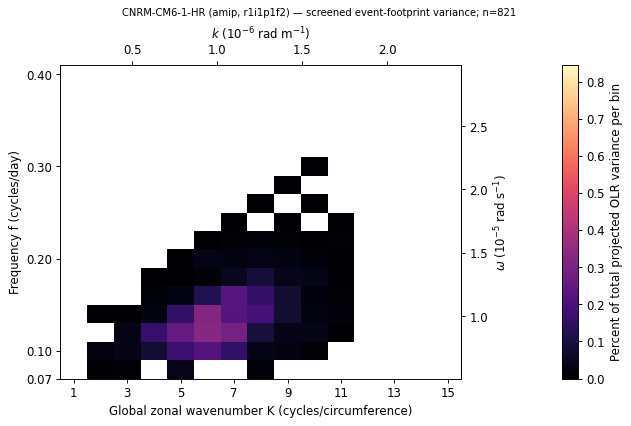

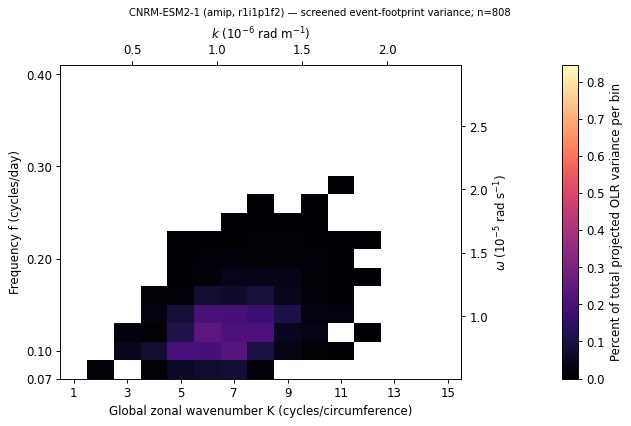

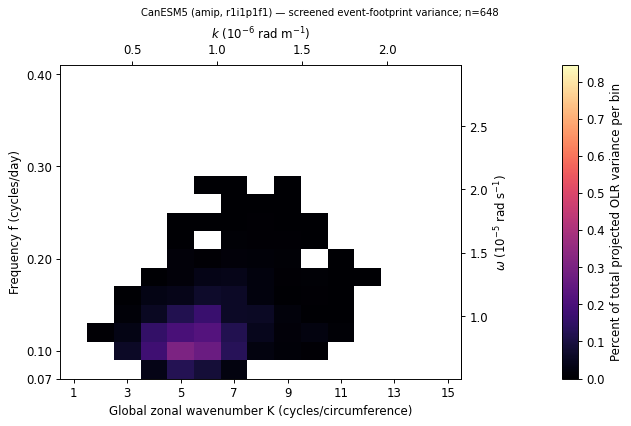

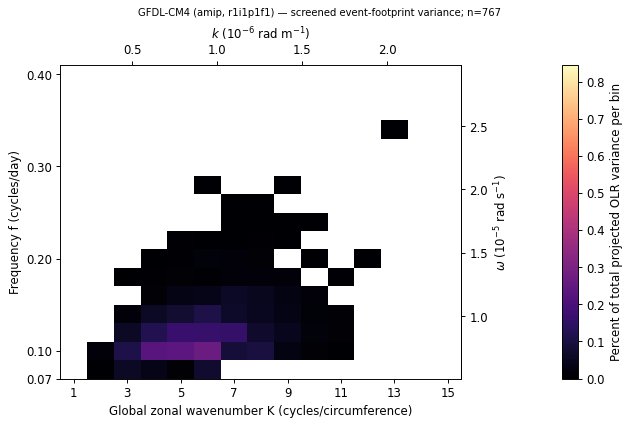

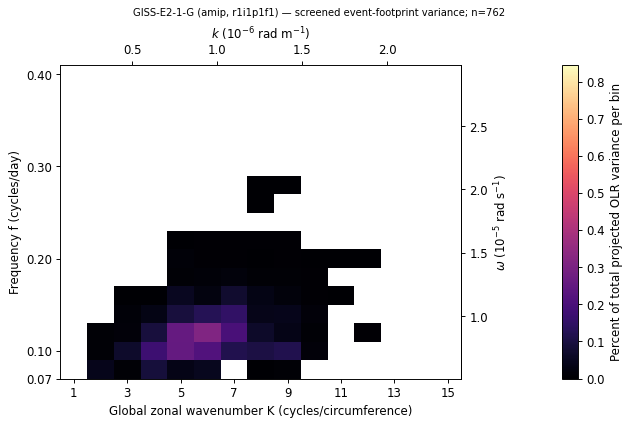

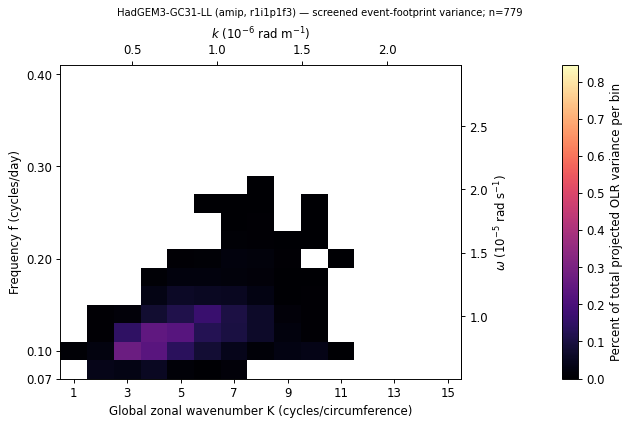

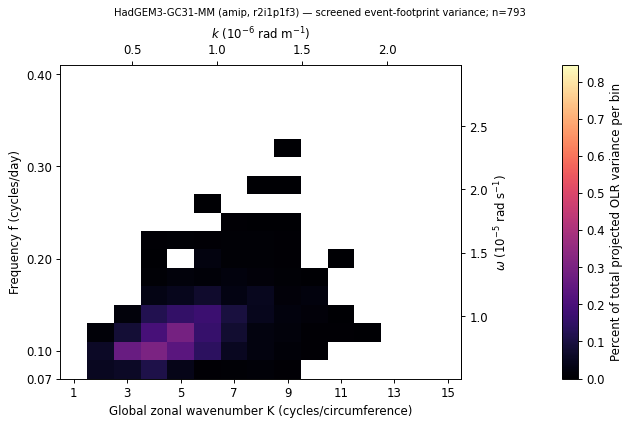

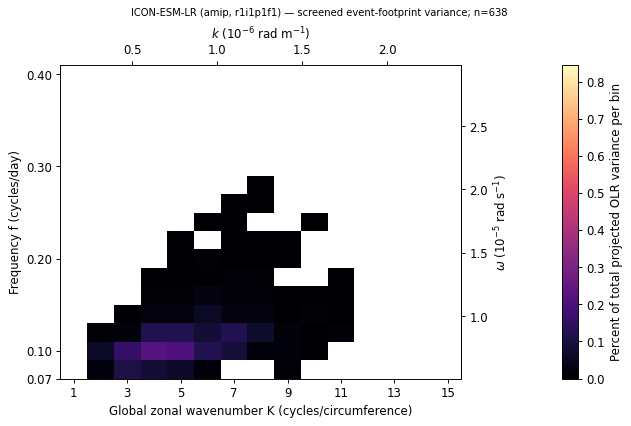

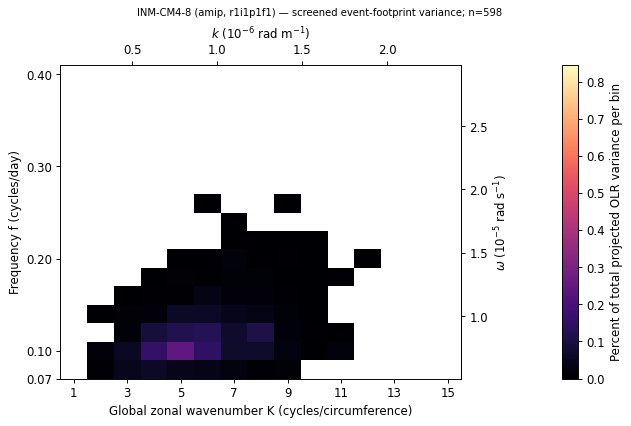

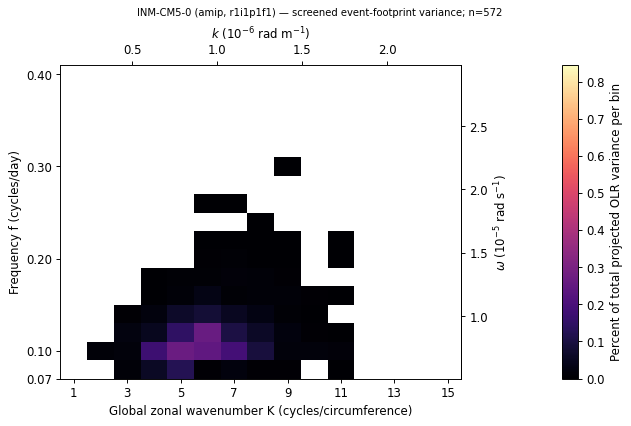

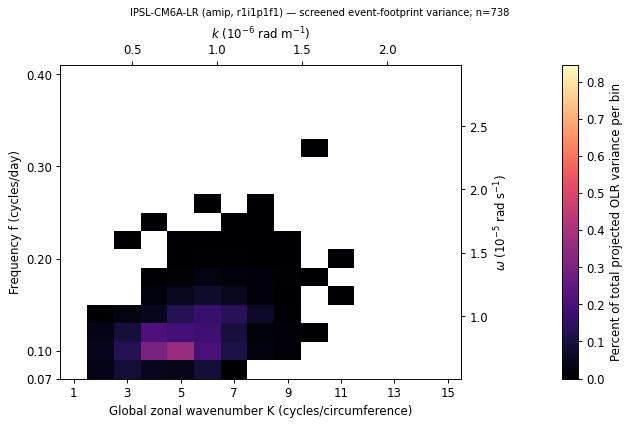

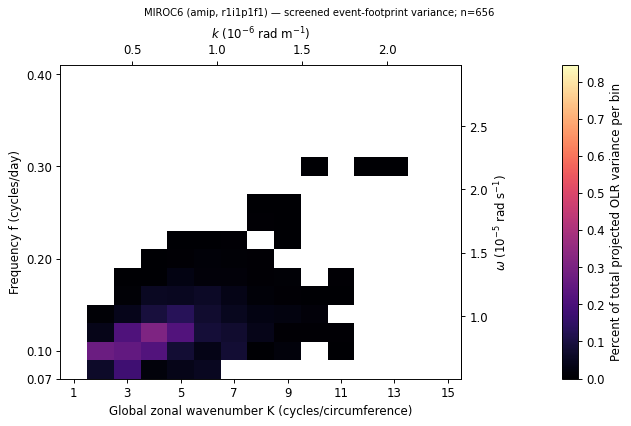

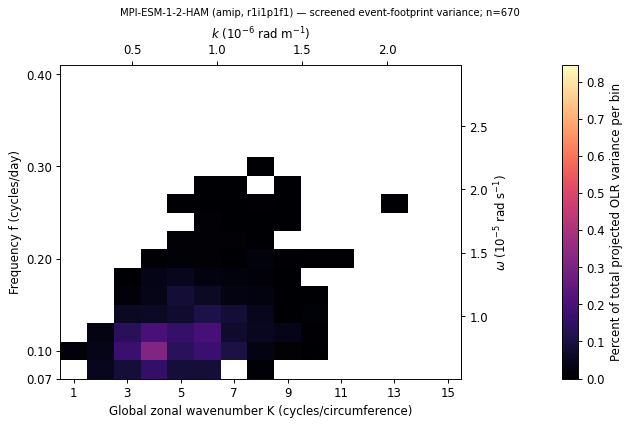

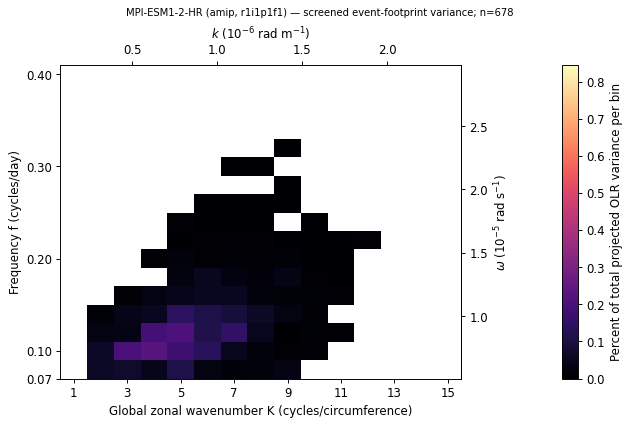

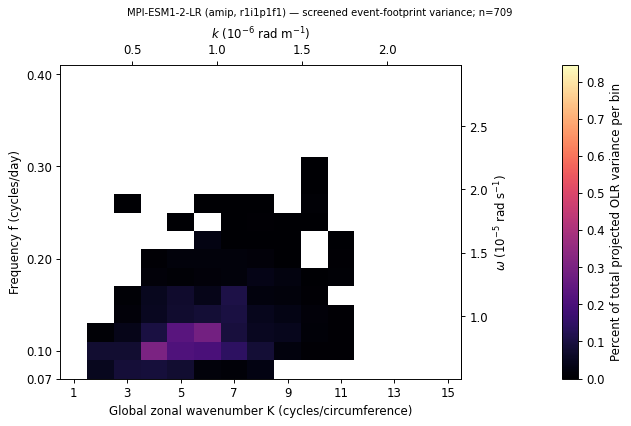

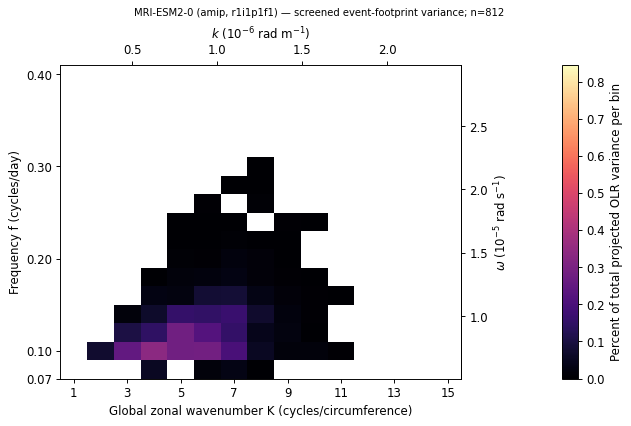

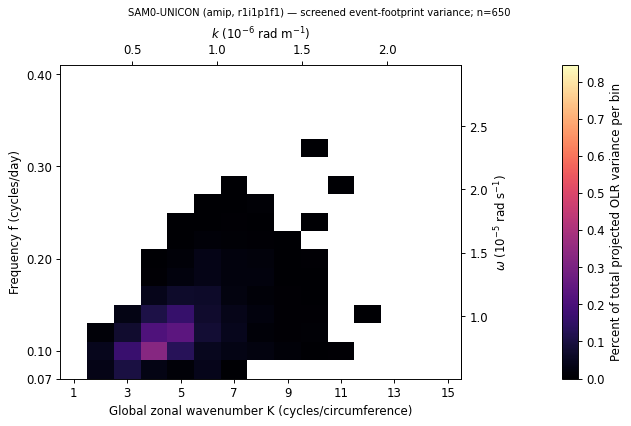

In [5]:
plot_records("event", "amip")

## Raw 96-day symmetric OLR spectral variance

Every Fourier component contributes, including intervals with no detected event. A red background is expected.

### NOAA observations

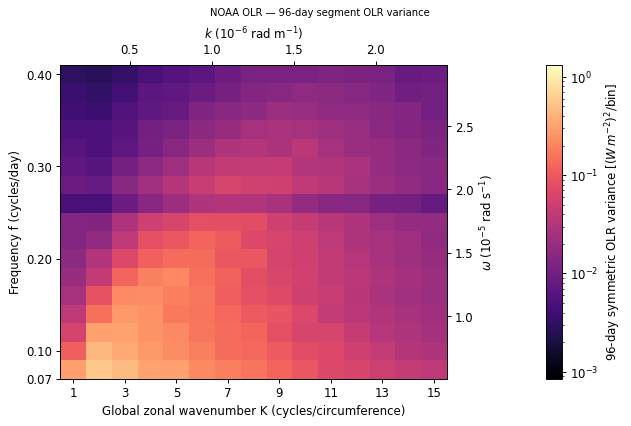

In [6]:
plot_records("raw", "observations")

### Historical models (34 records)

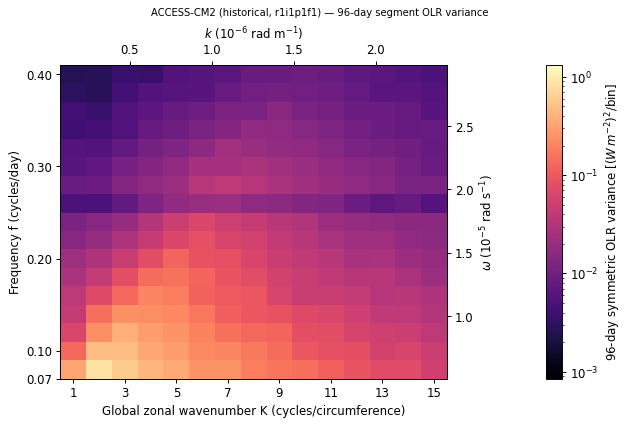

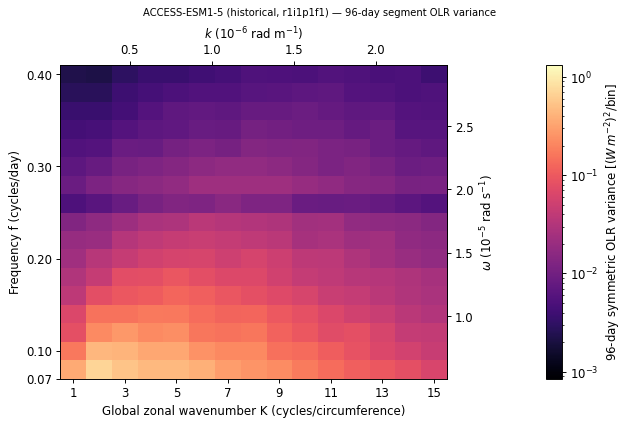

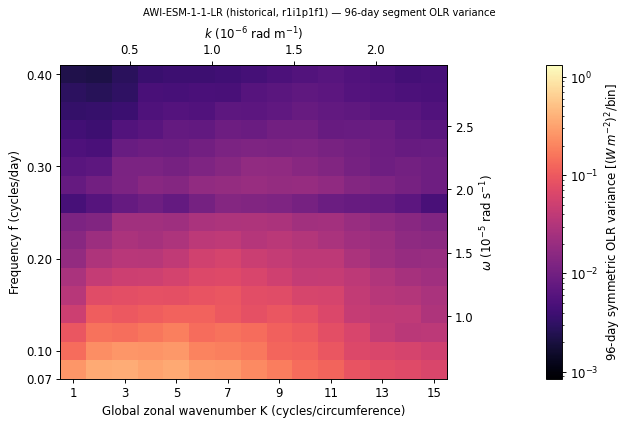

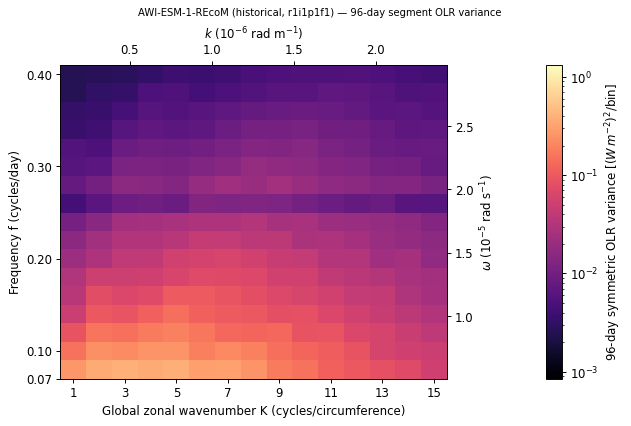

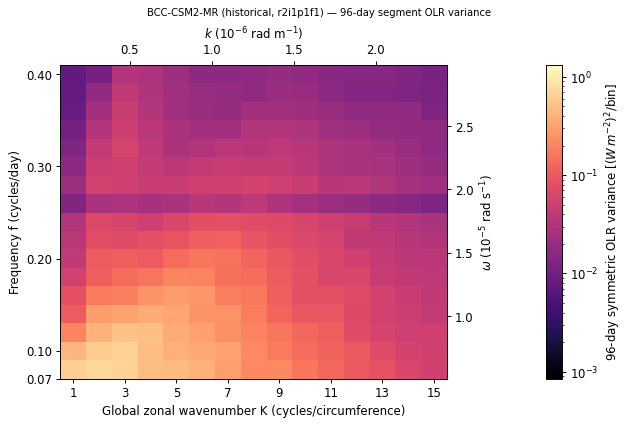

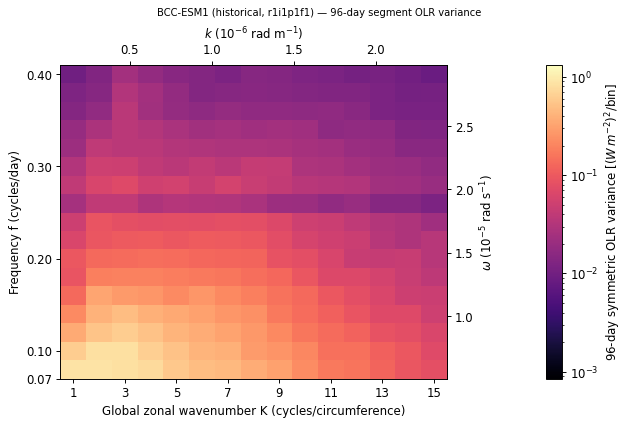

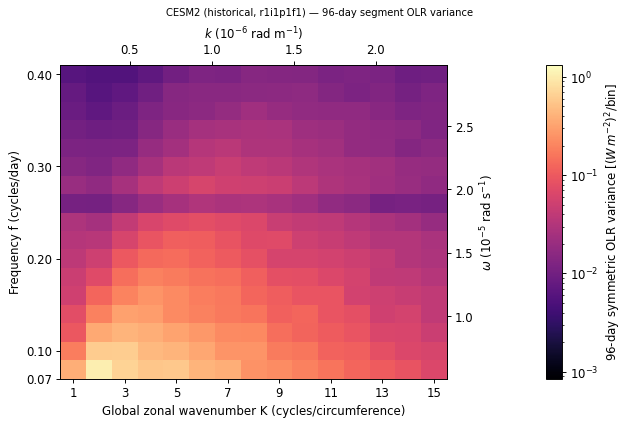

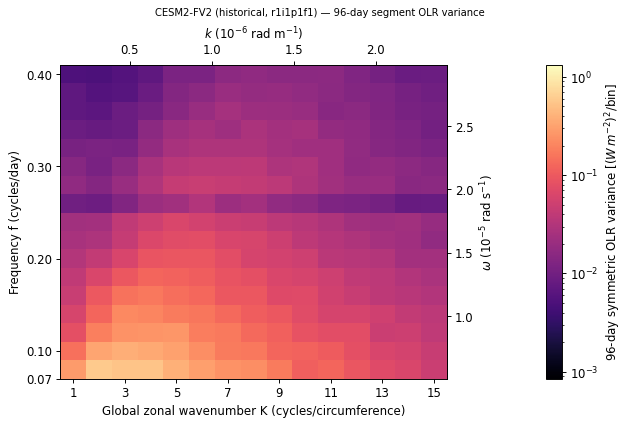

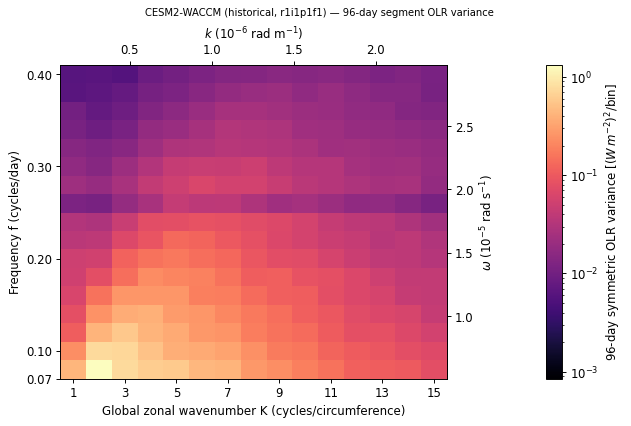

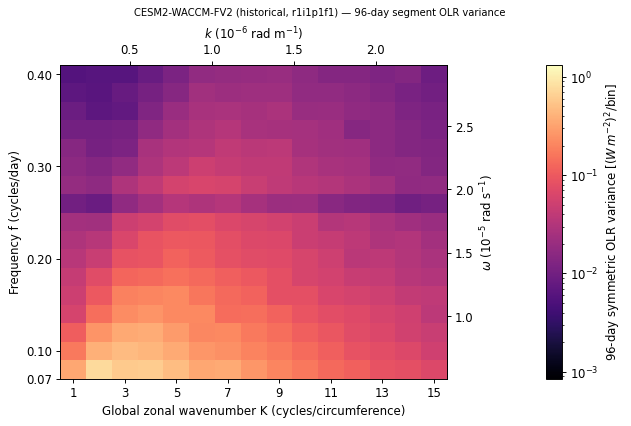

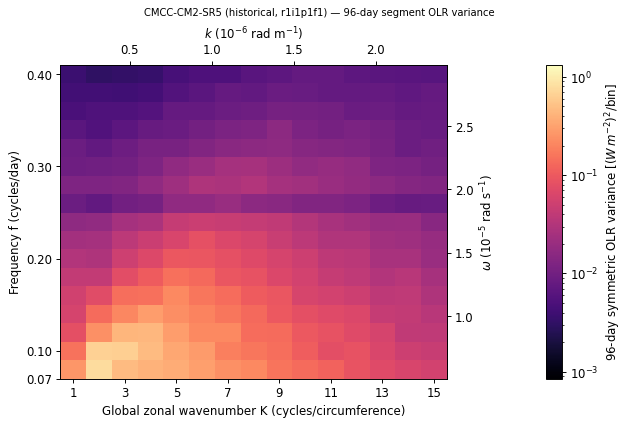

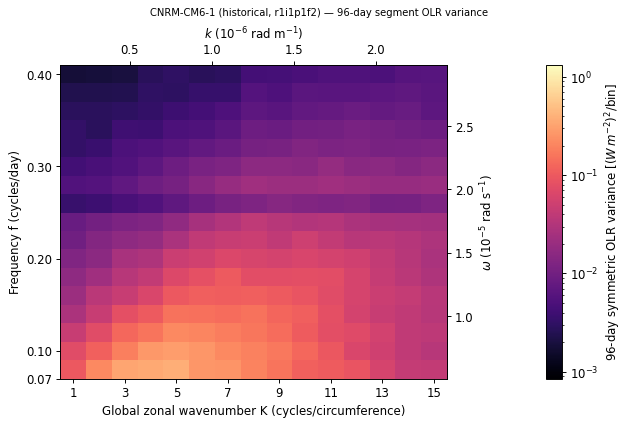

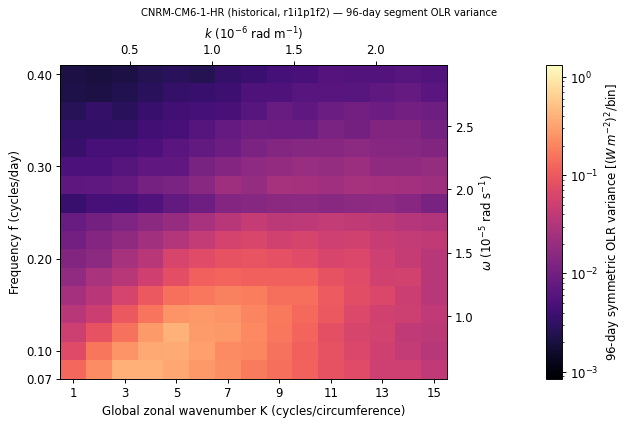

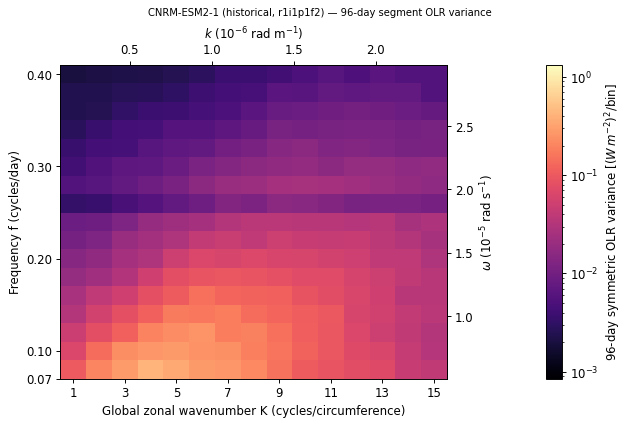

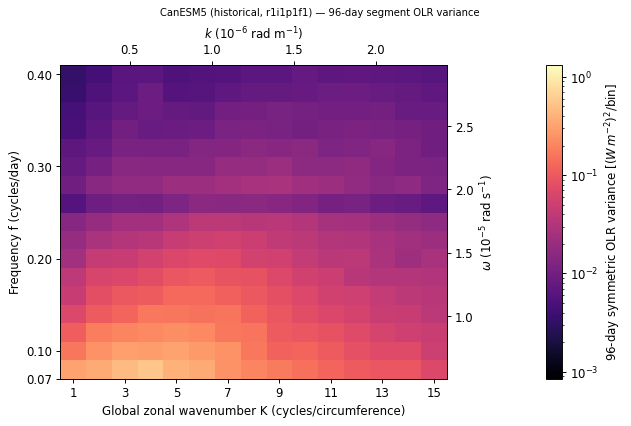

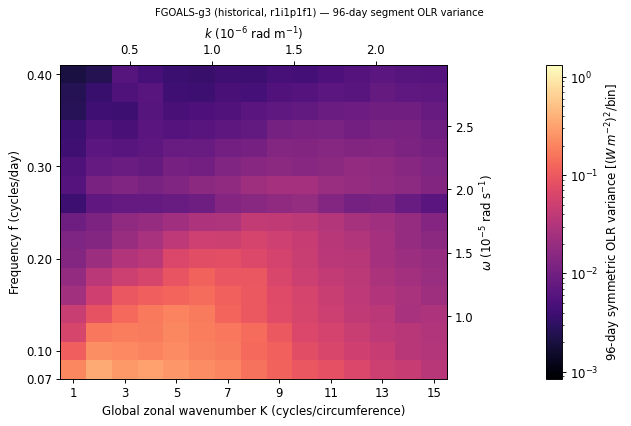

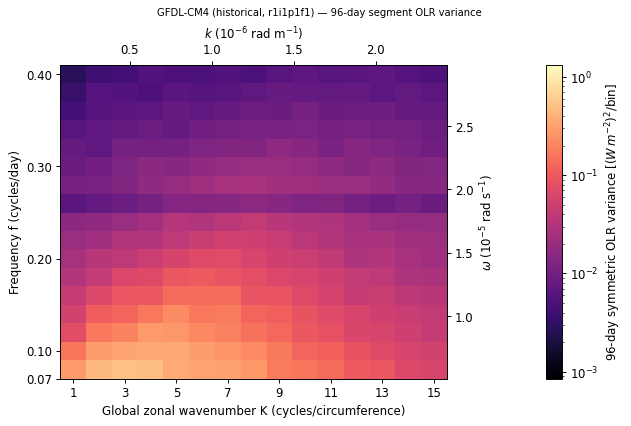

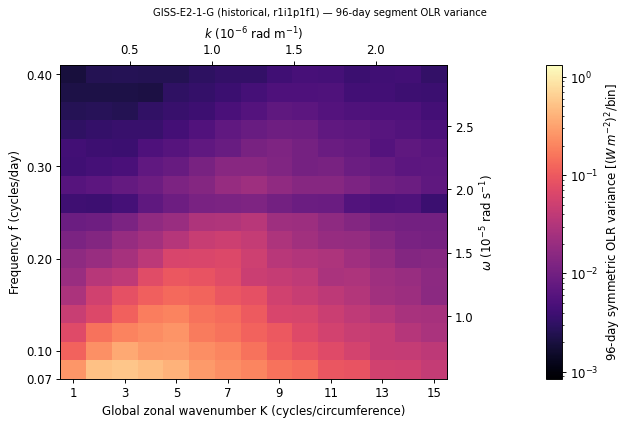

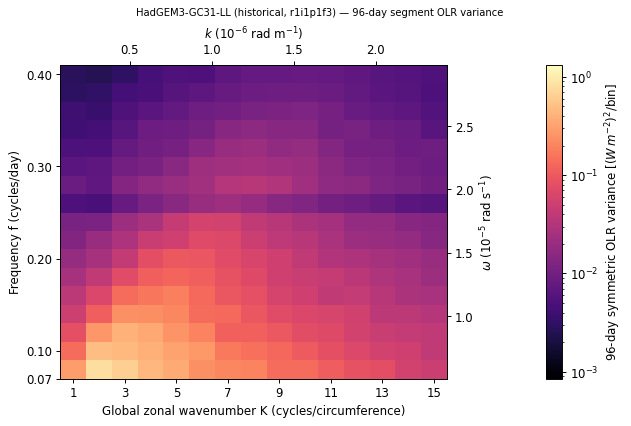

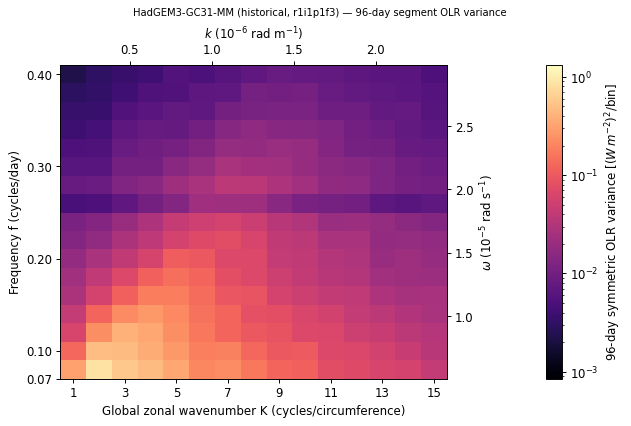

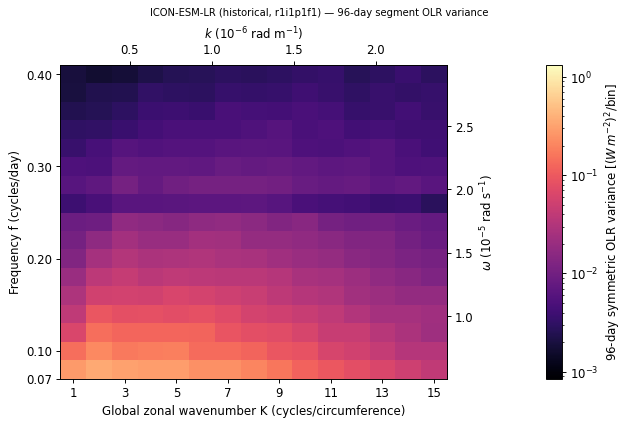

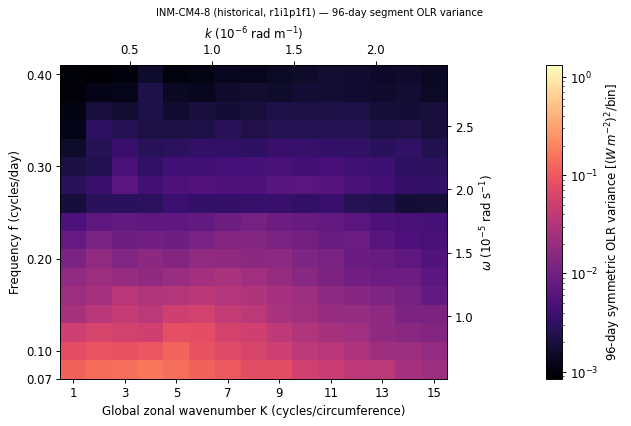

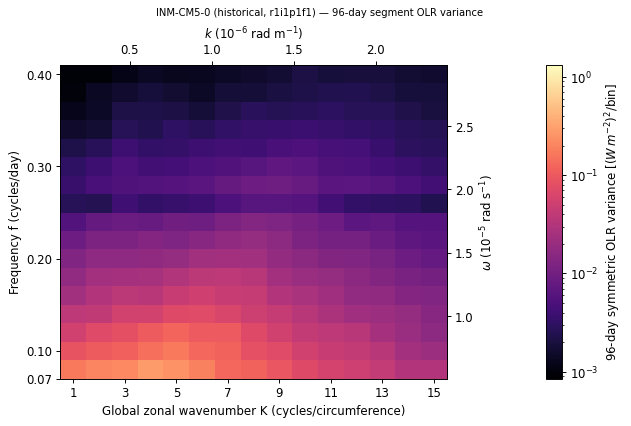

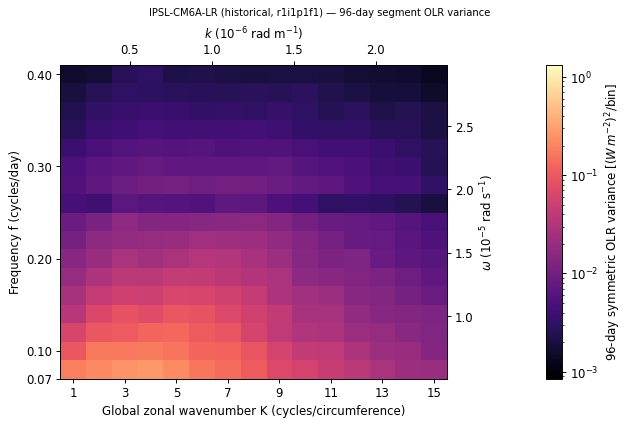

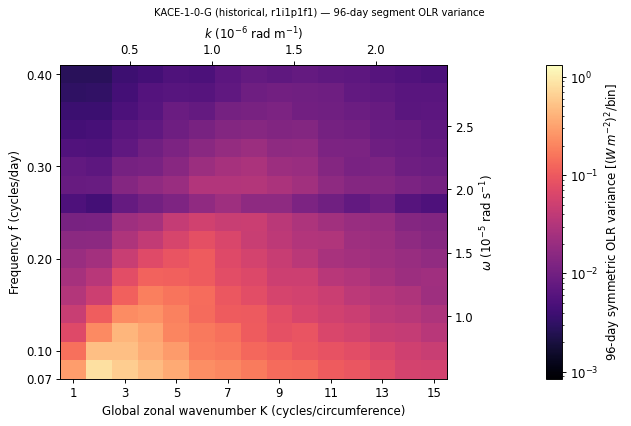

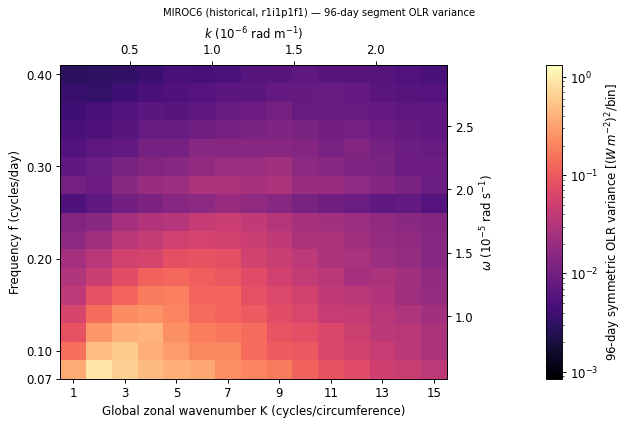

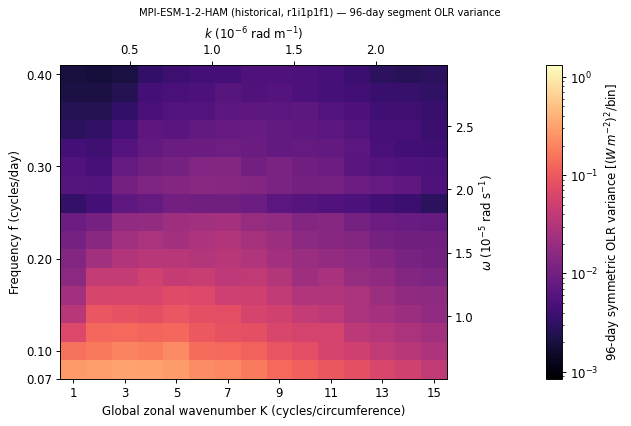

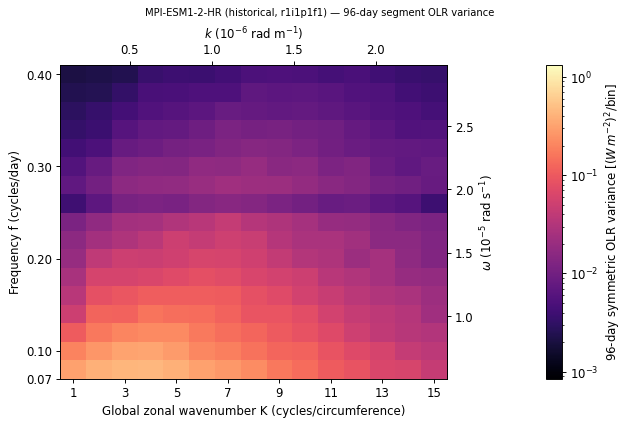

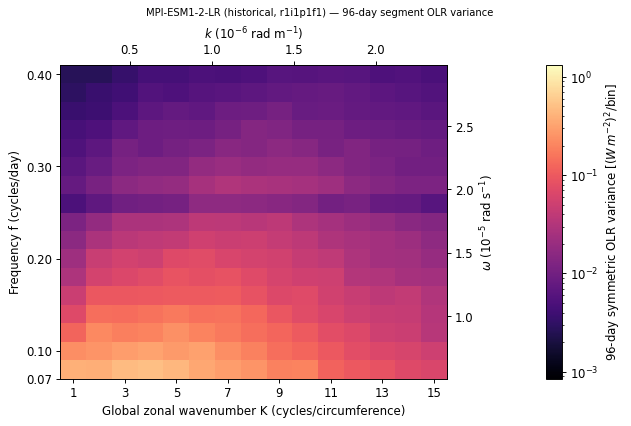

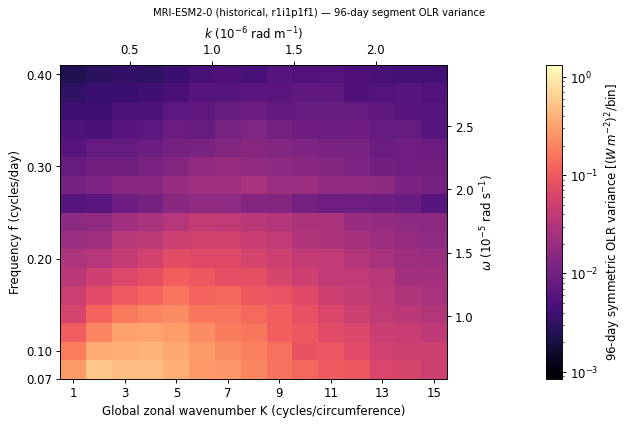

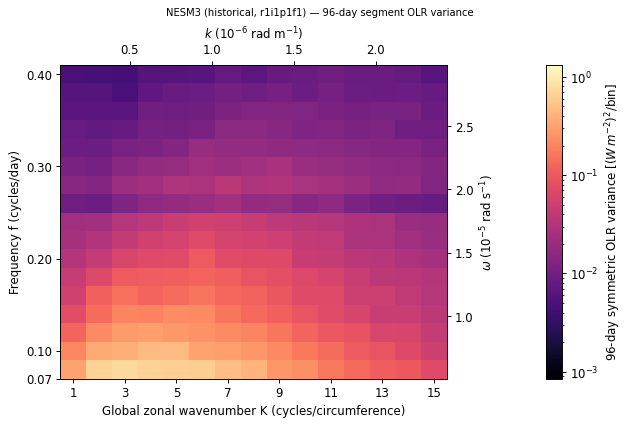

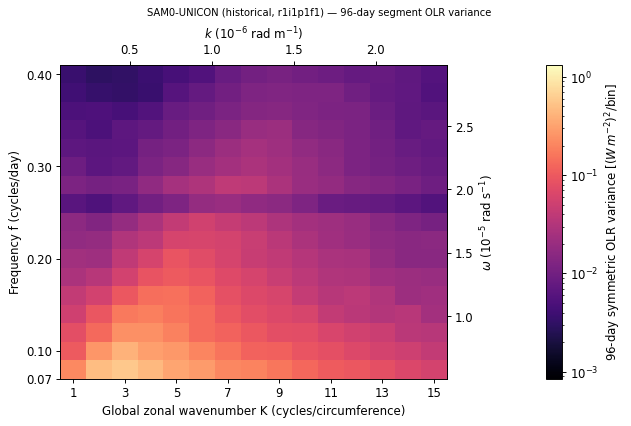

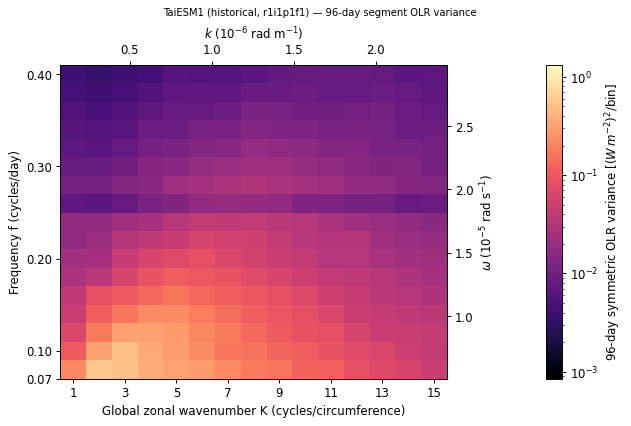

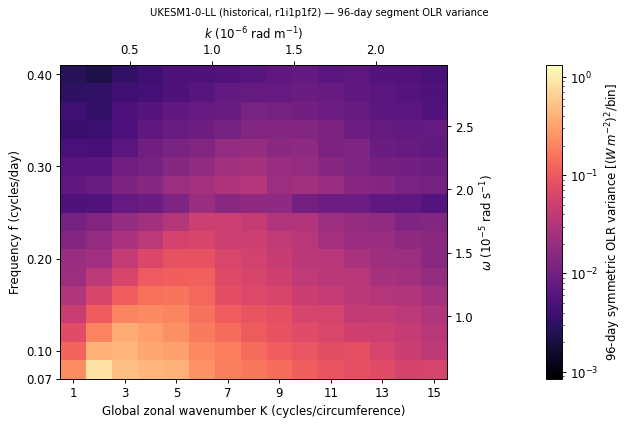

In [7]:
plot_records("raw", "historical")

### AMIP models (25 records)

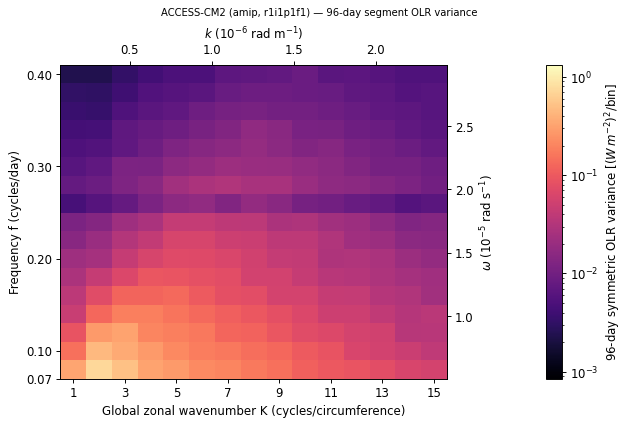

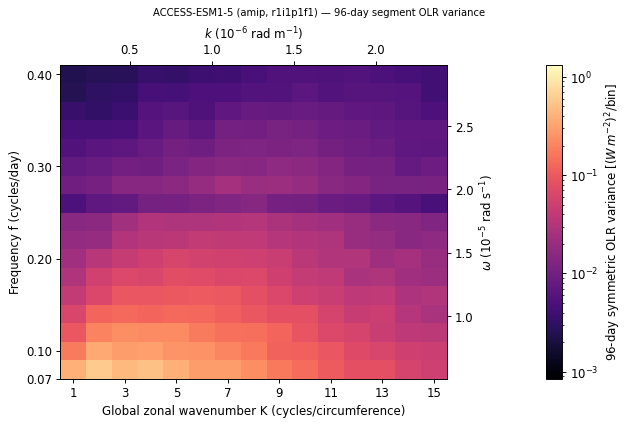

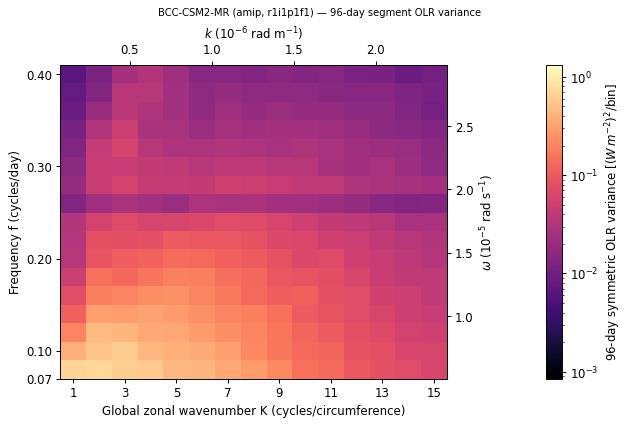

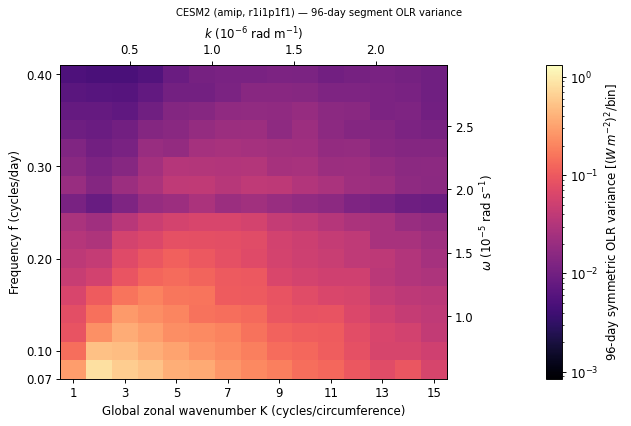

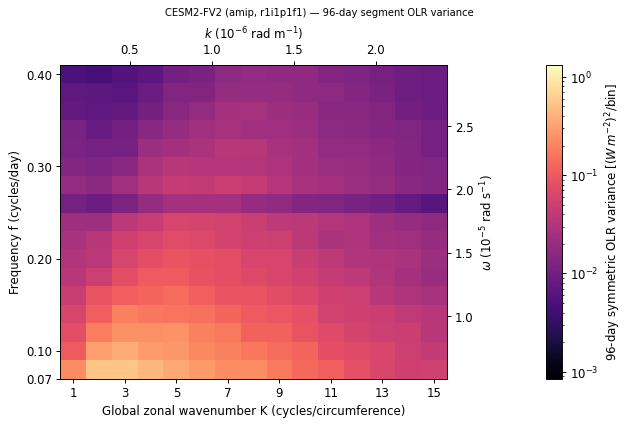

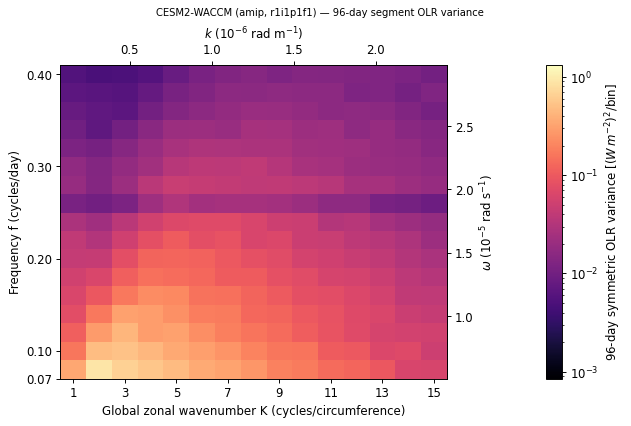

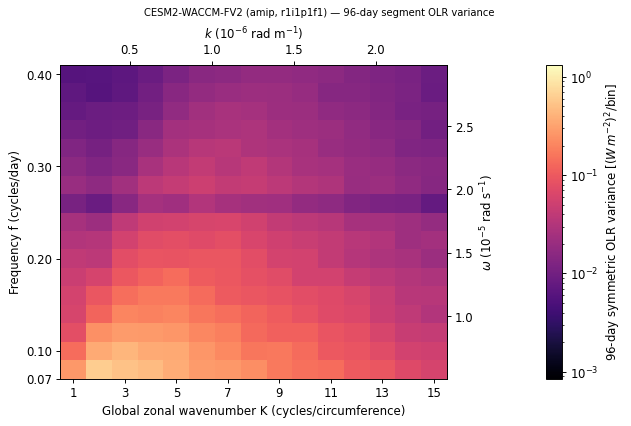

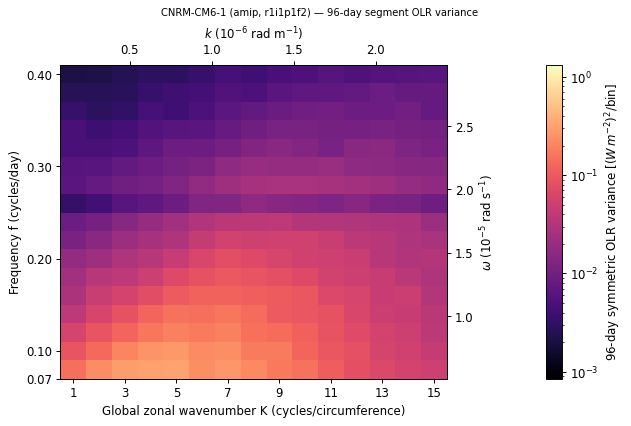

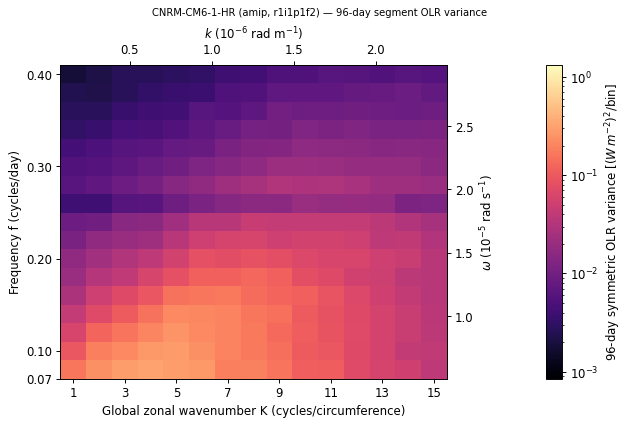

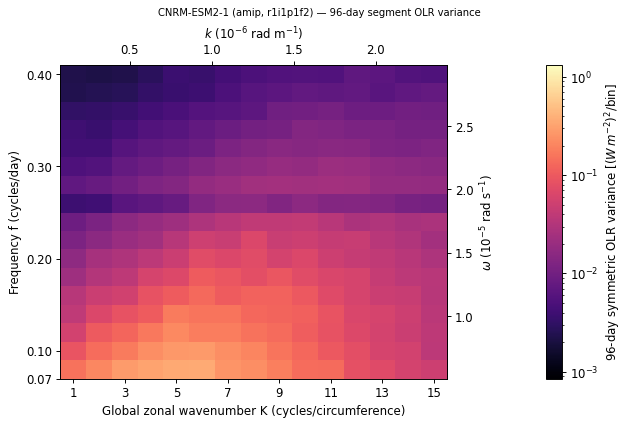

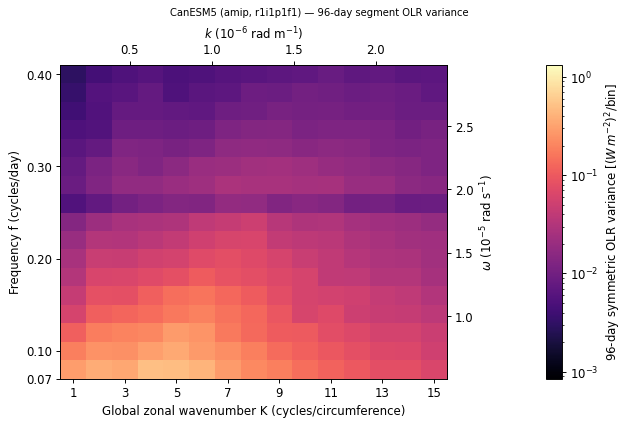

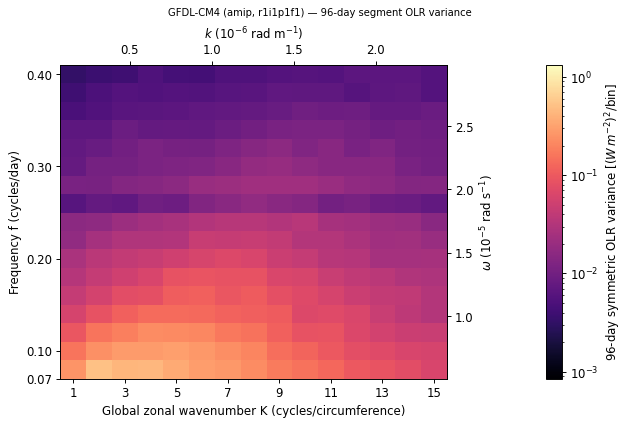

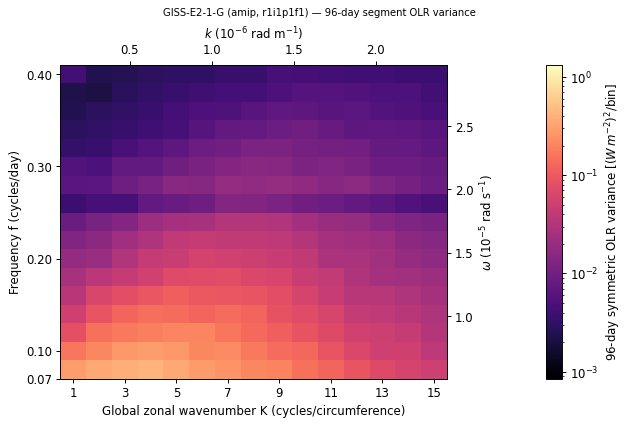

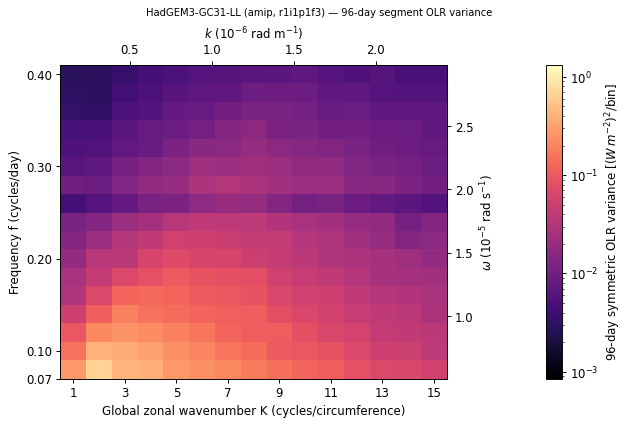

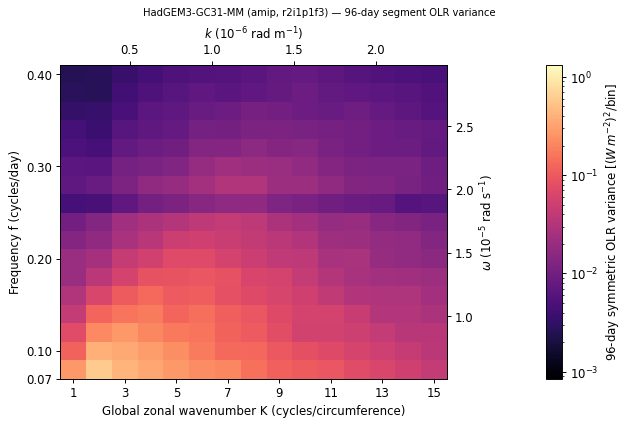

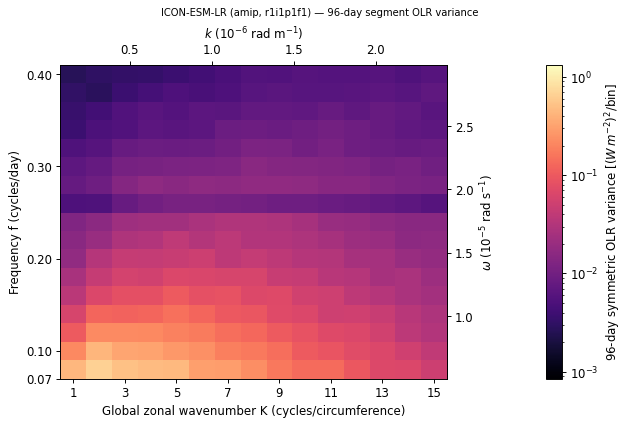

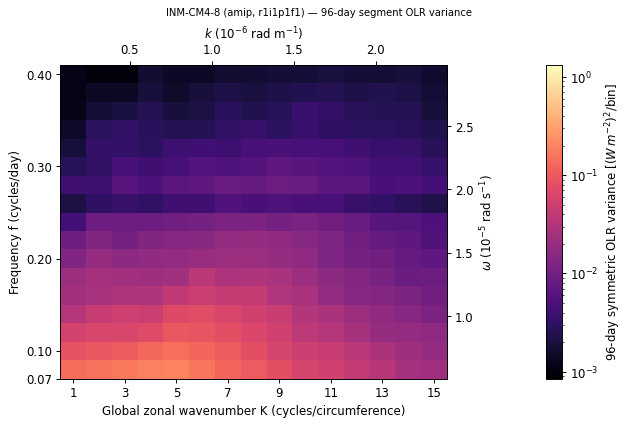

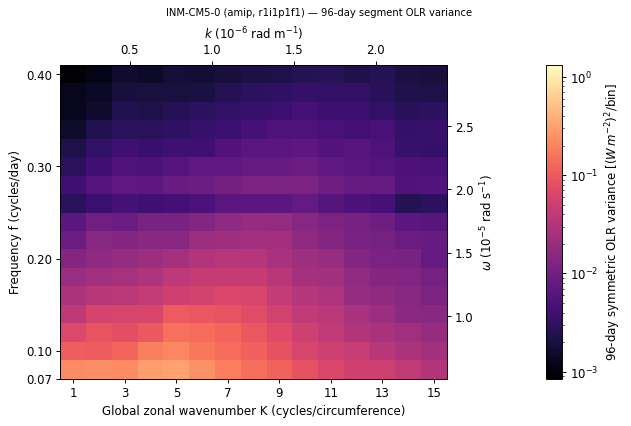

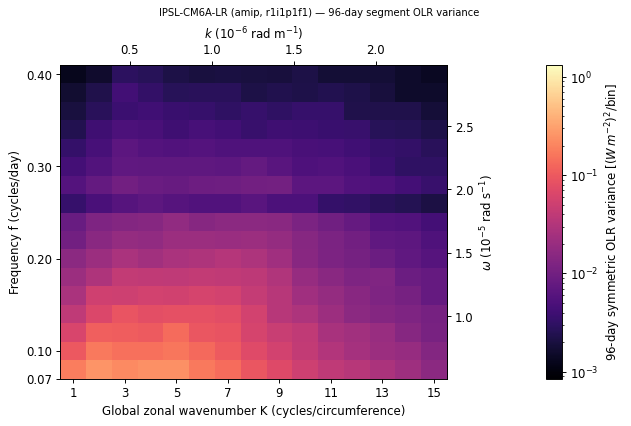

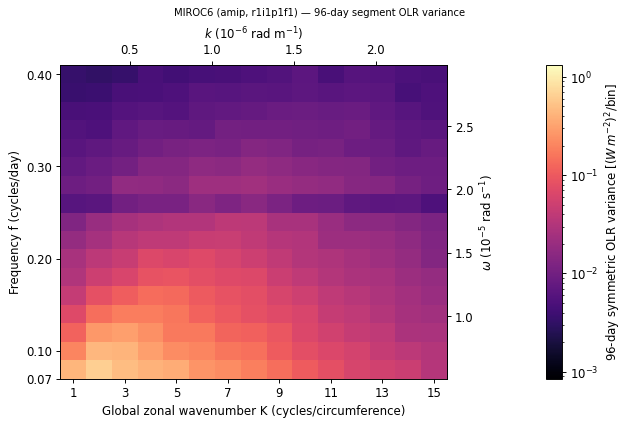

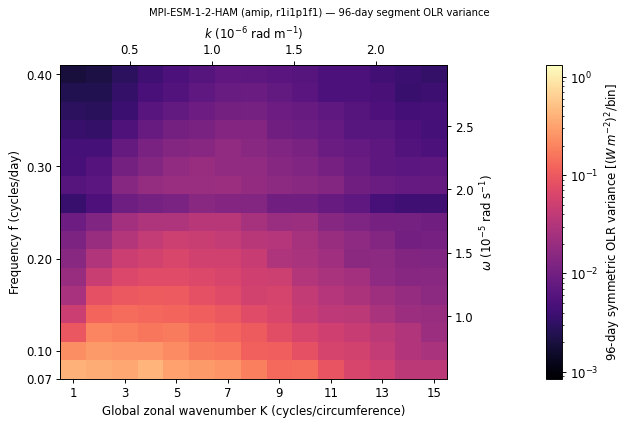

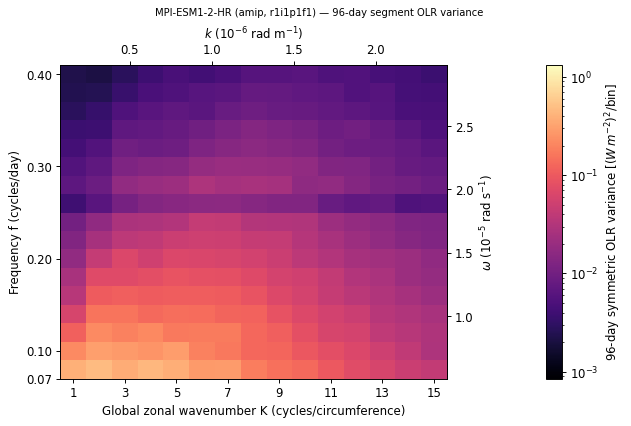

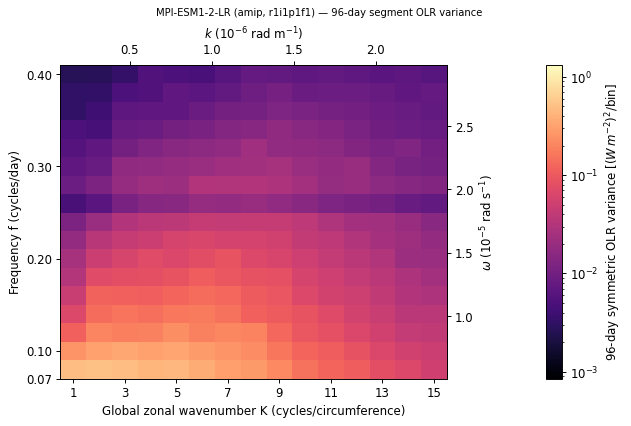

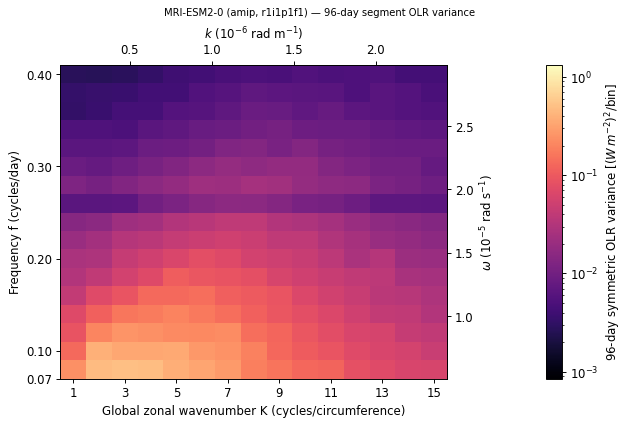

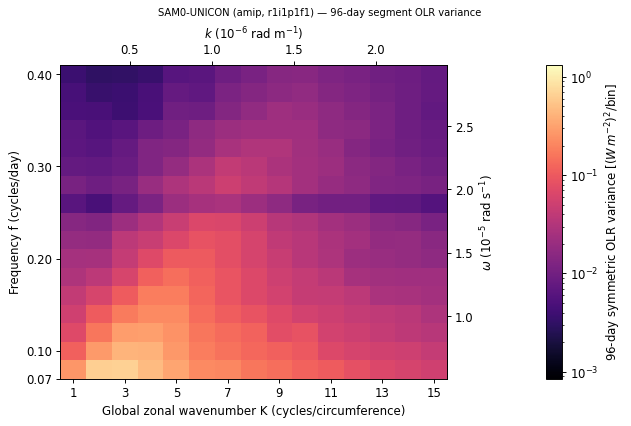

In [8]:
plot_records("raw", "amip")

## WK-style OLR spectral excess

The binned symmetric spectrum is divided by the binned smooth pooled background. Ratios above one indicate excess power, not an event count or a formal p-value.

### NOAA observations

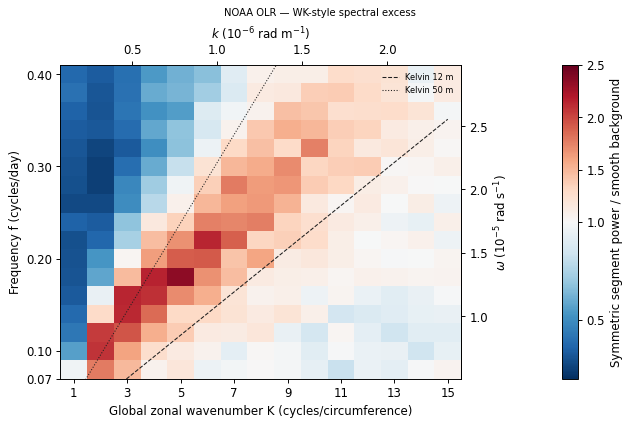

In [9]:
plot_records("excess", "observations")

### Historical models (34 records)

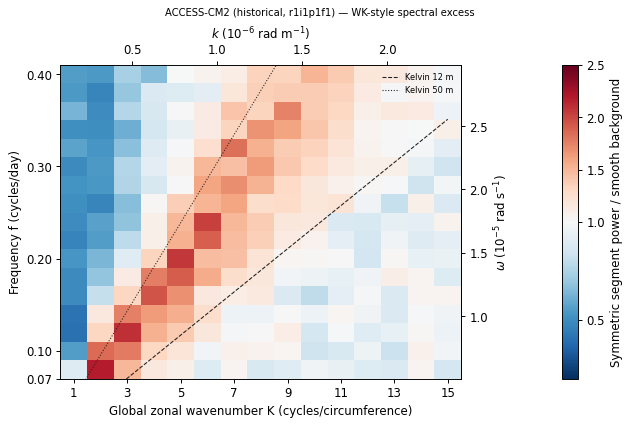

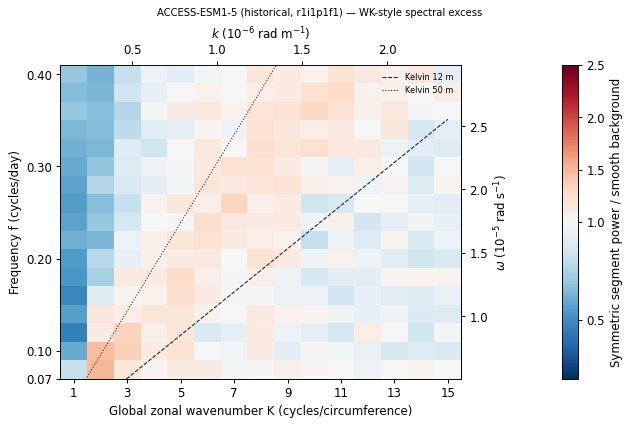

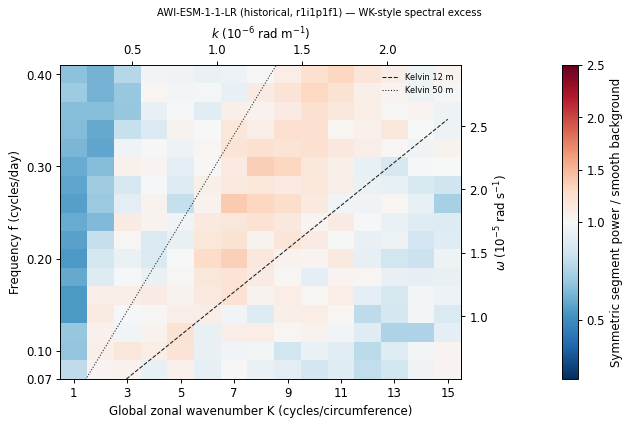

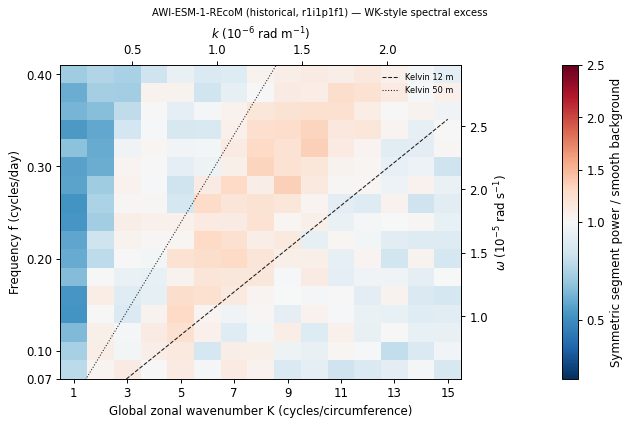

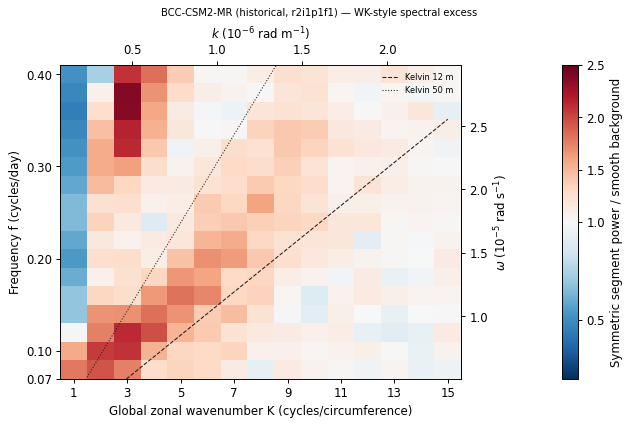

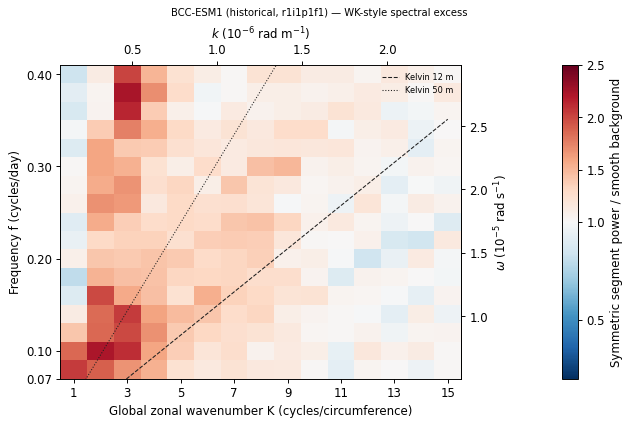

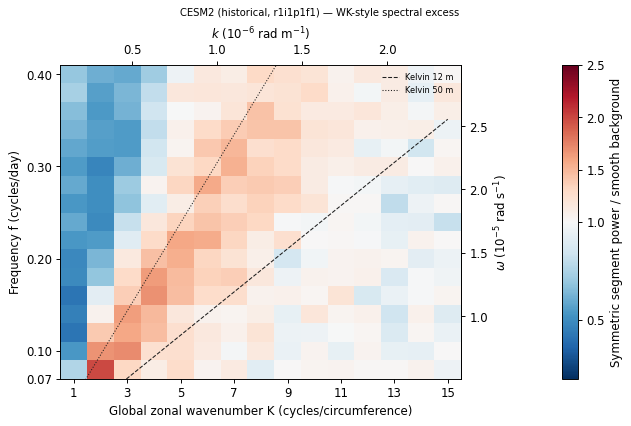

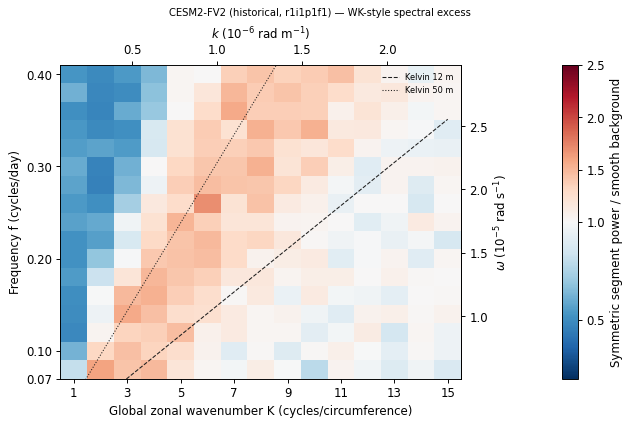

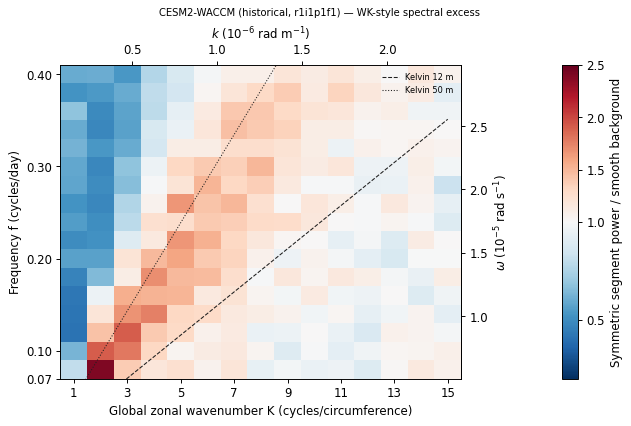

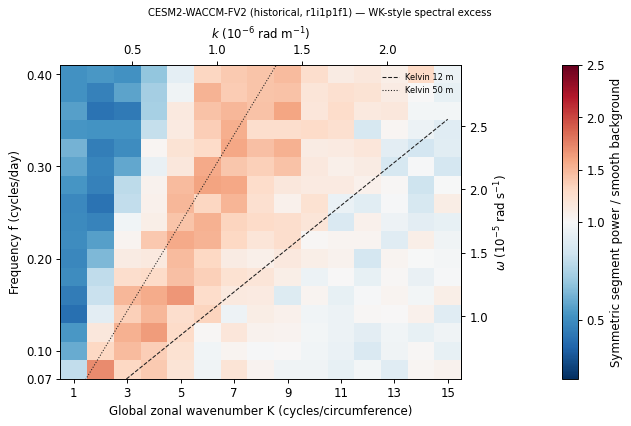

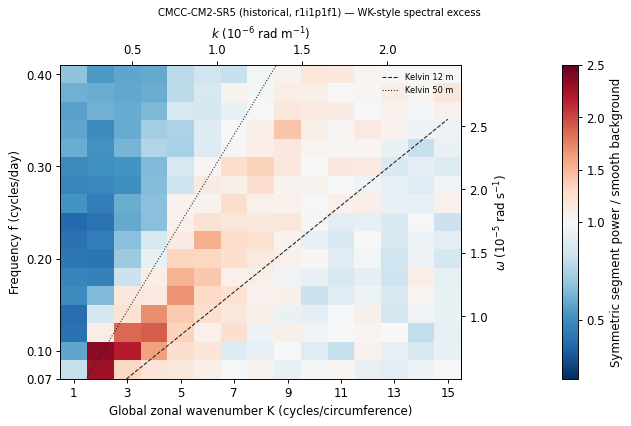

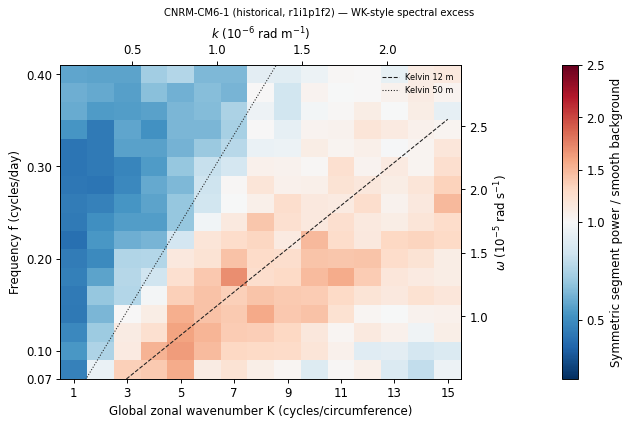

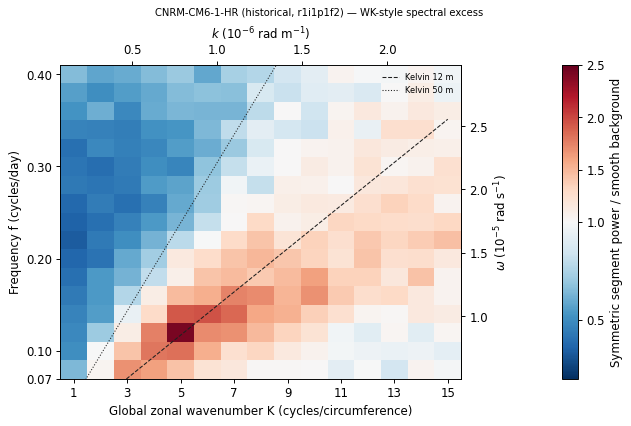

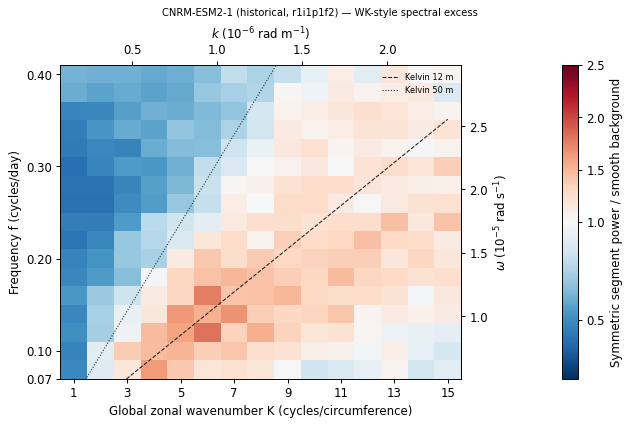

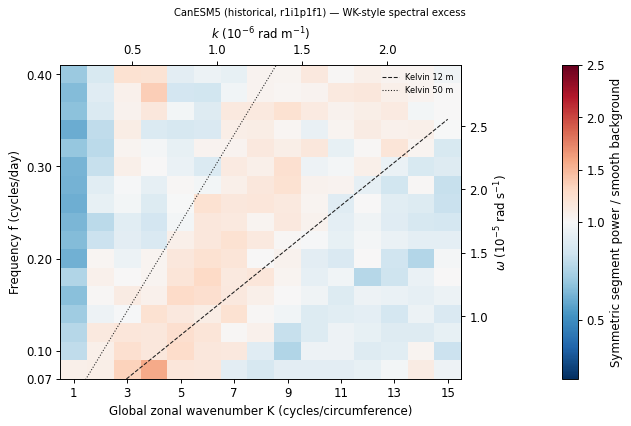

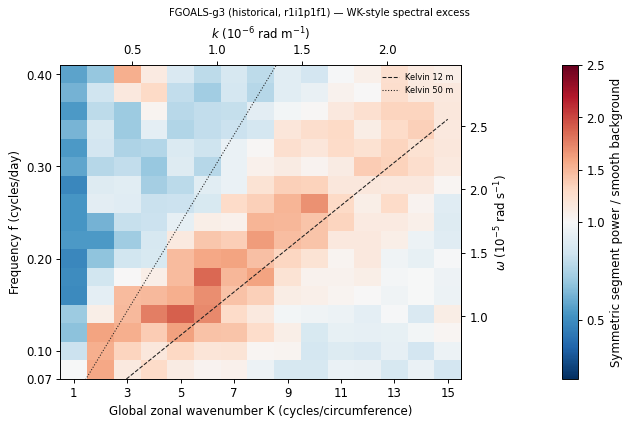

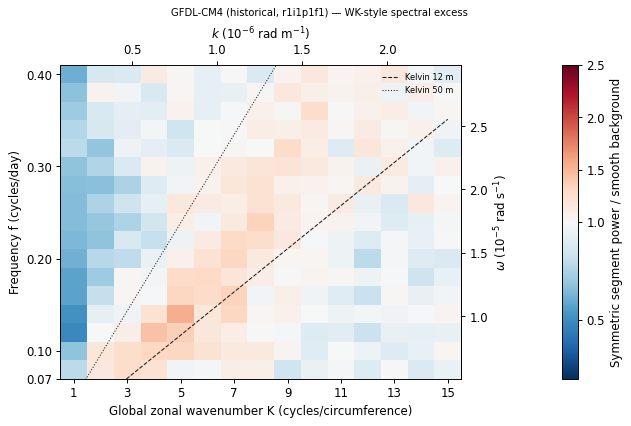

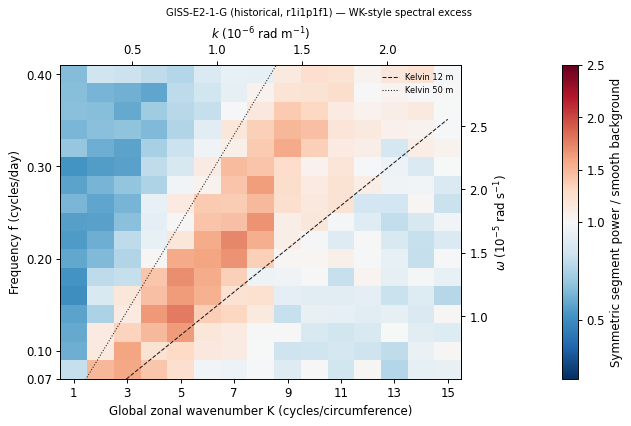

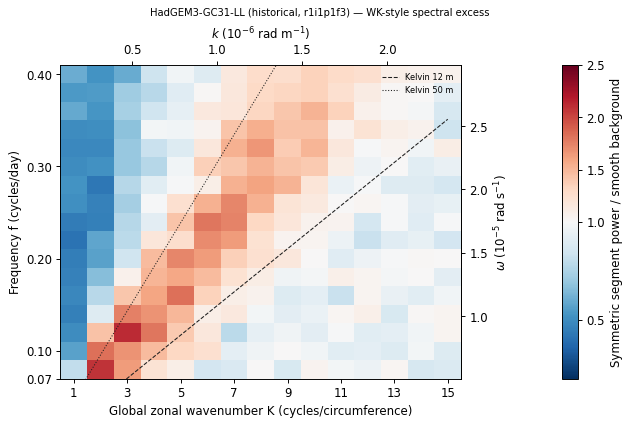

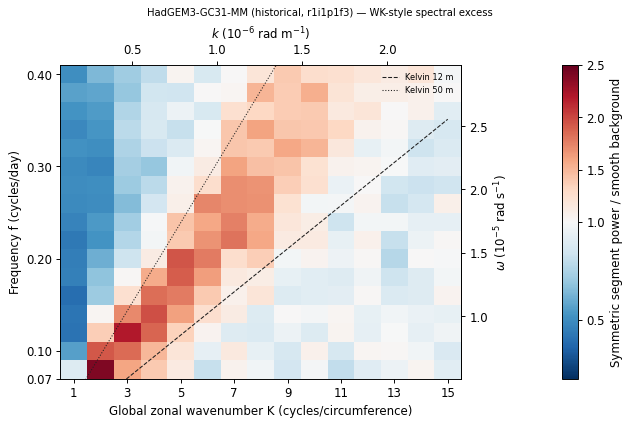

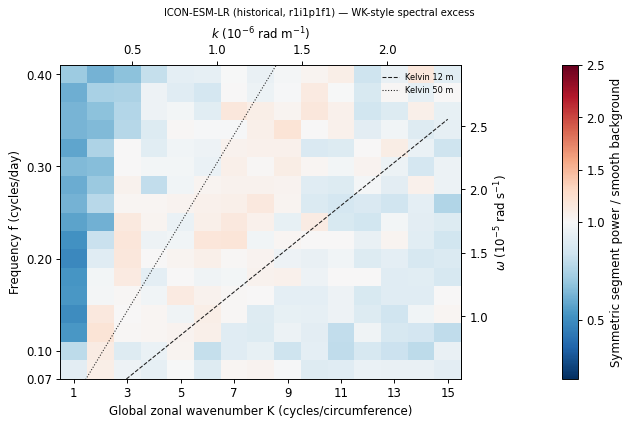

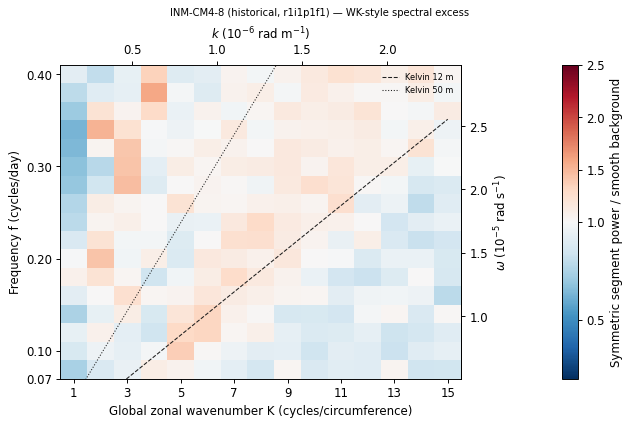

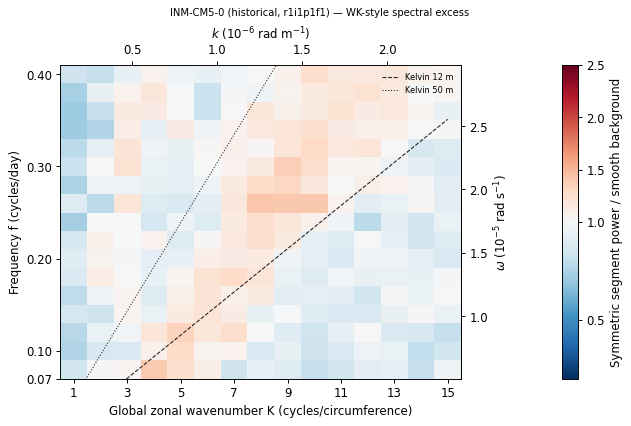

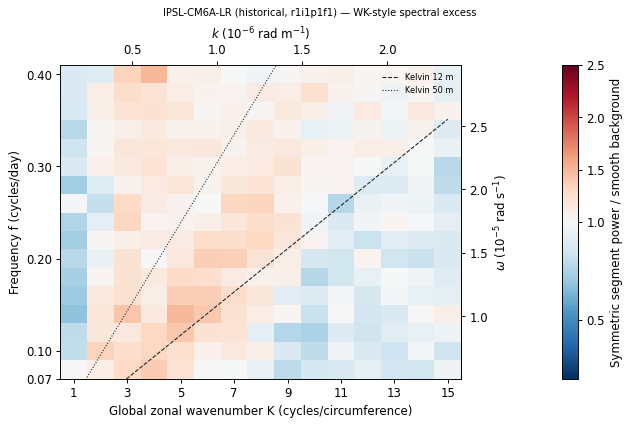

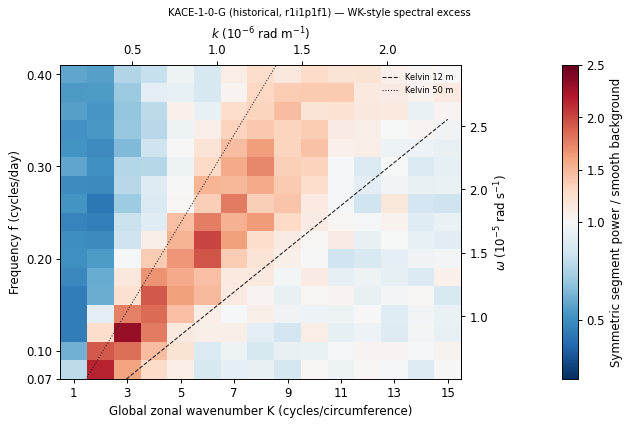

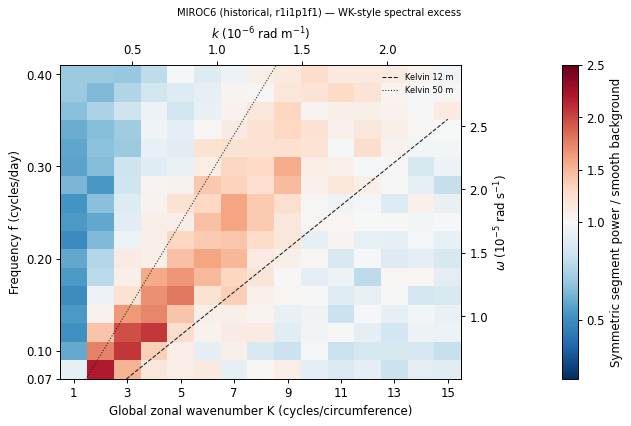

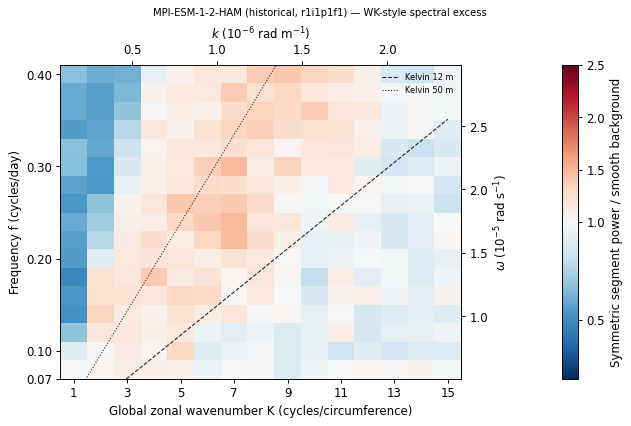

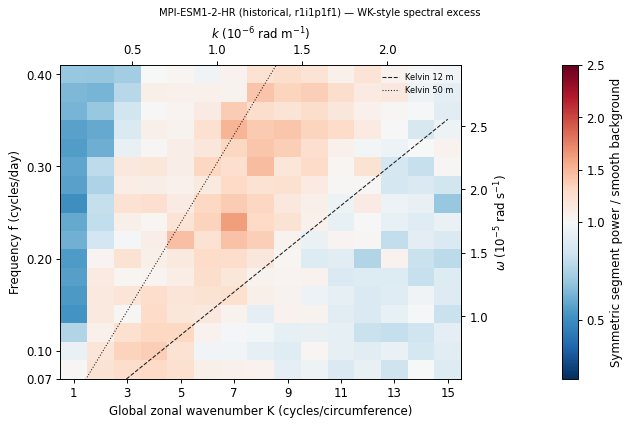

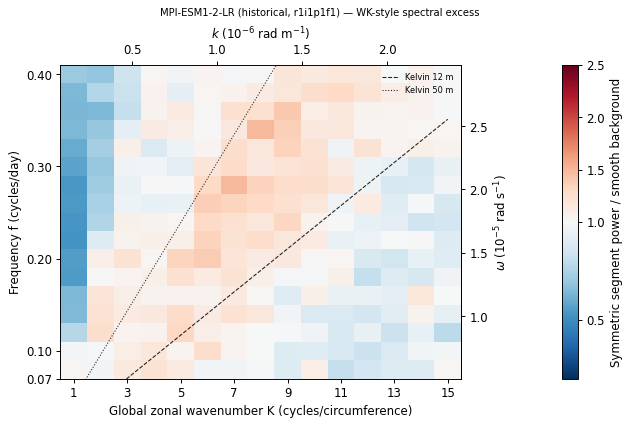

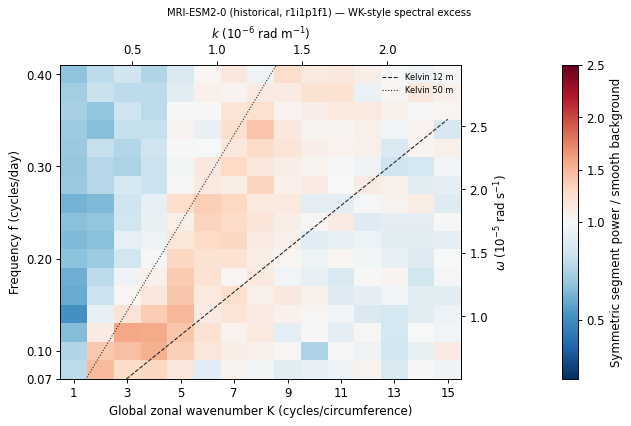

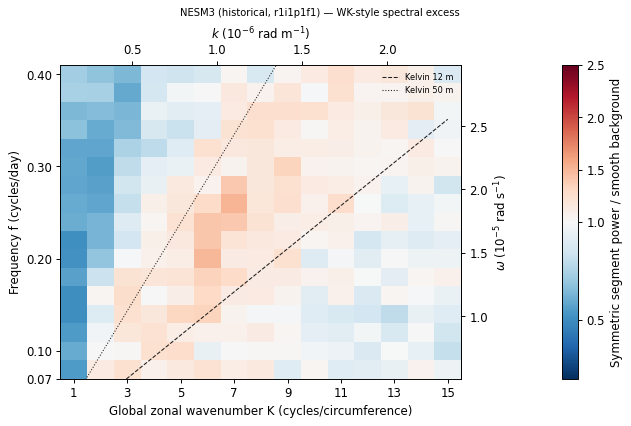

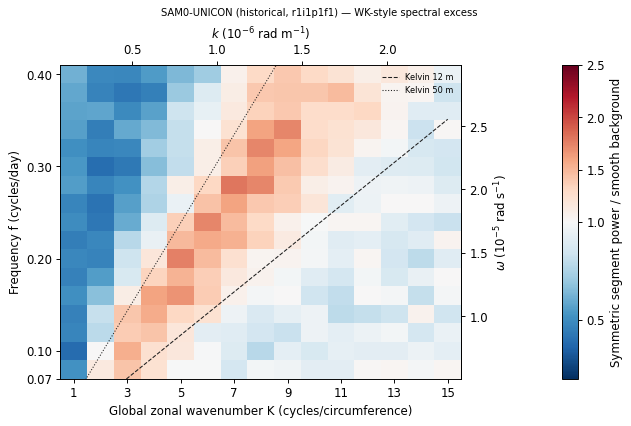

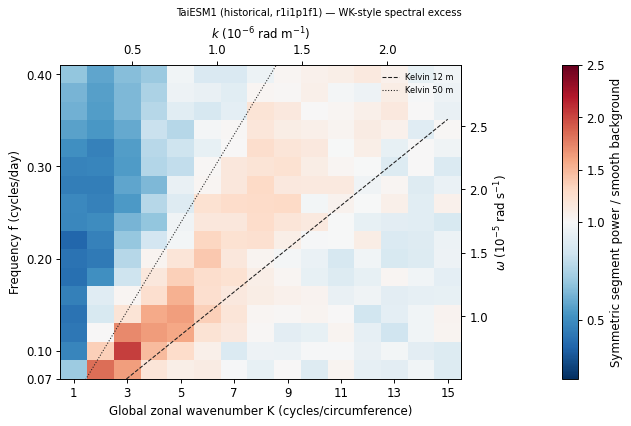

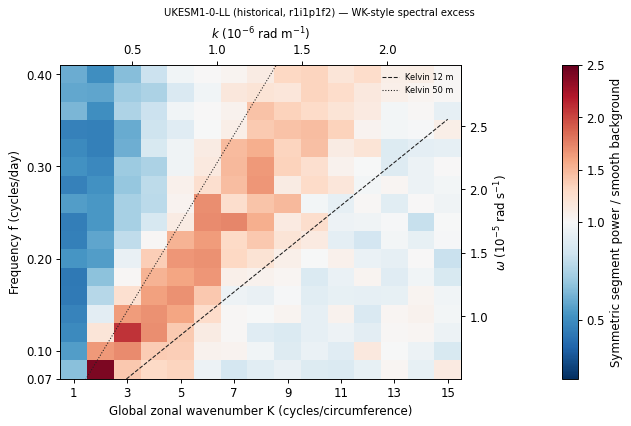

In [10]:
plot_records("excess", "historical")

### AMIP models (25 records)

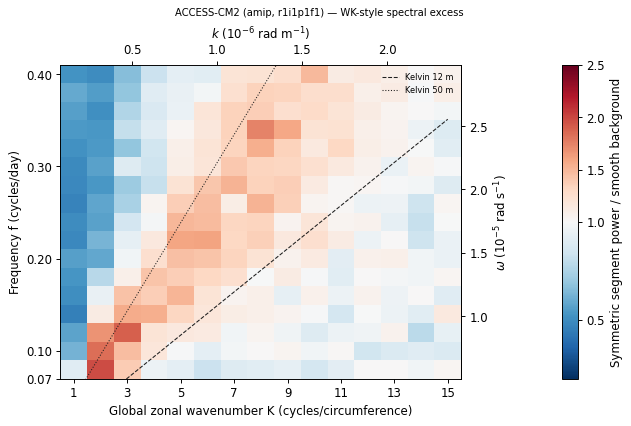

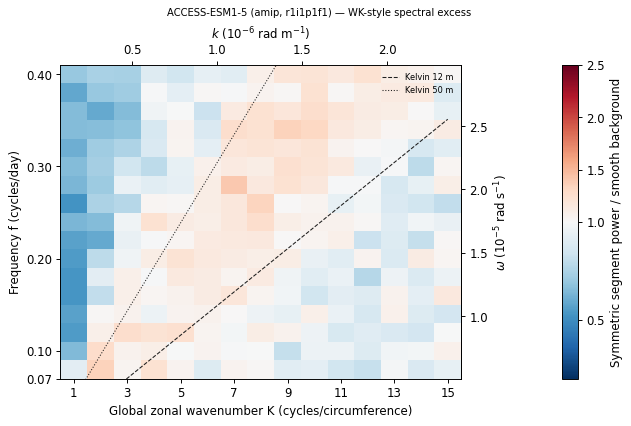

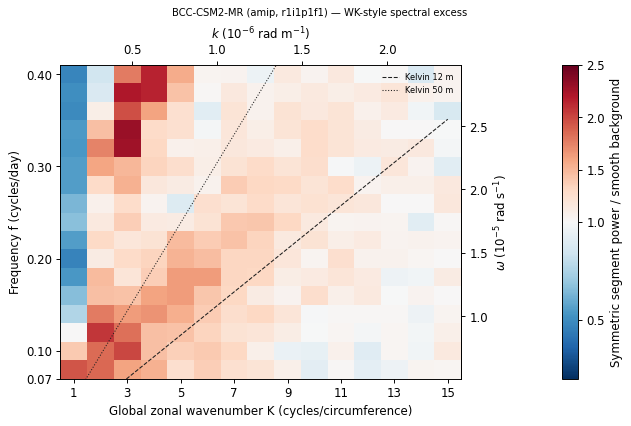

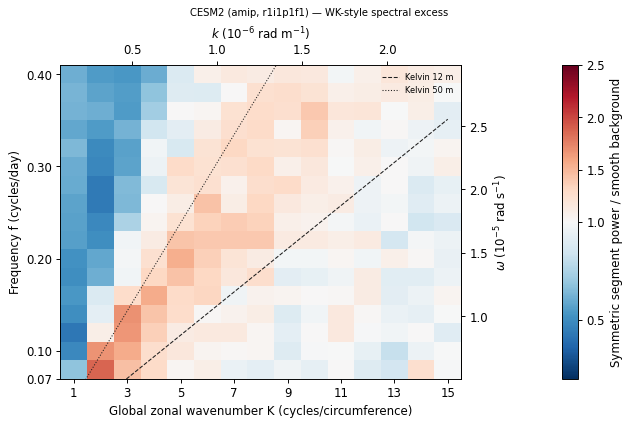

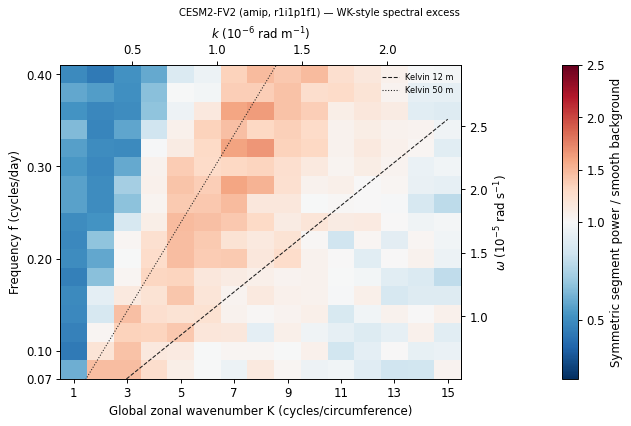

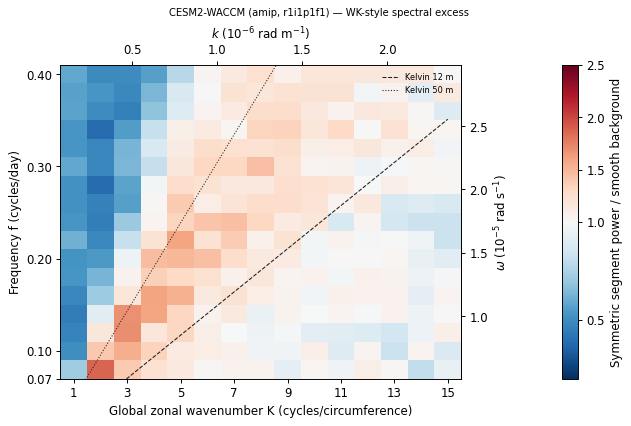

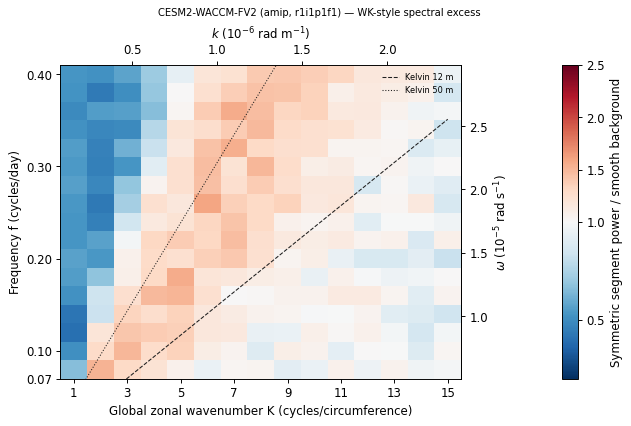

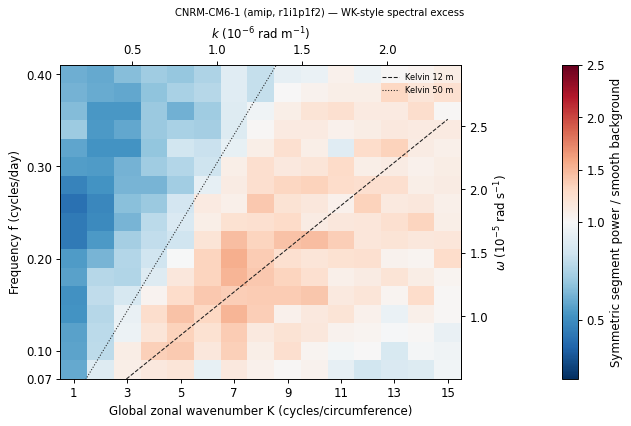

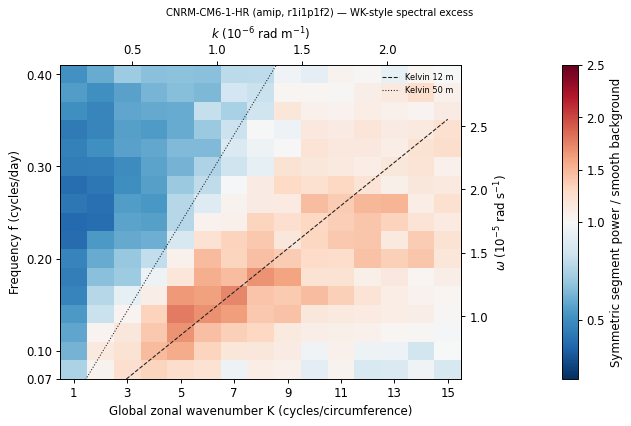

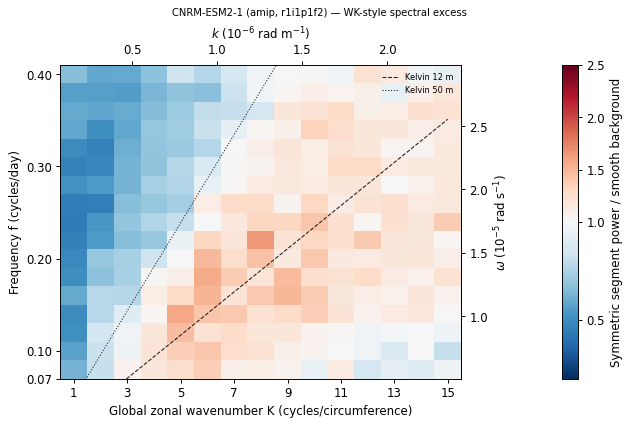

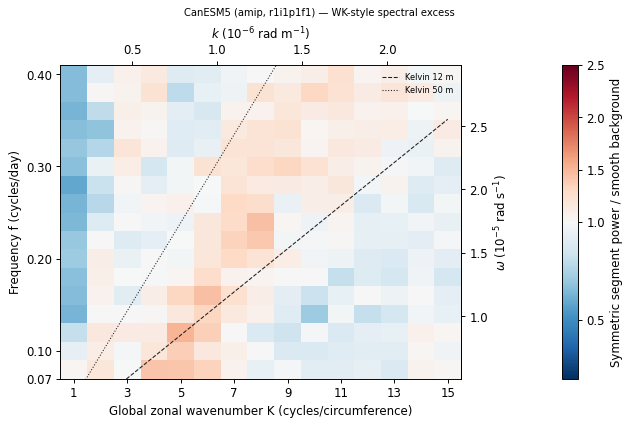

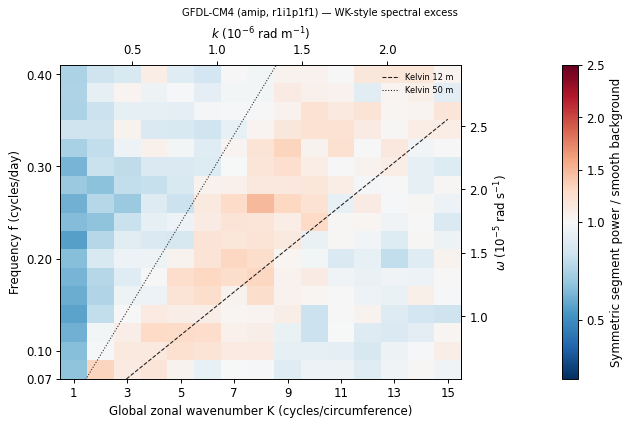

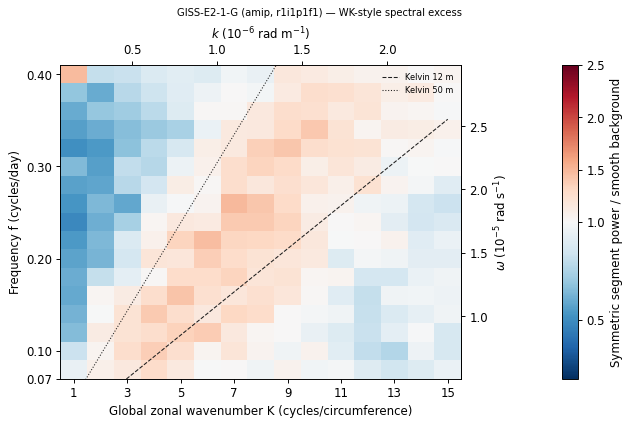

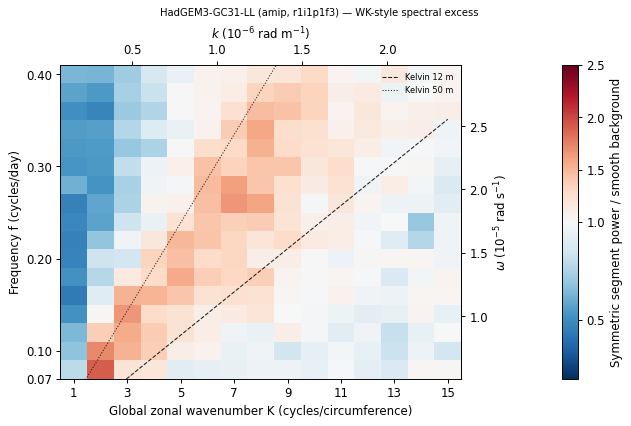

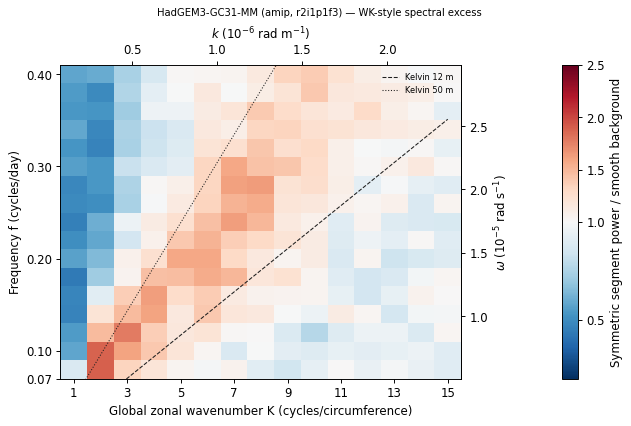

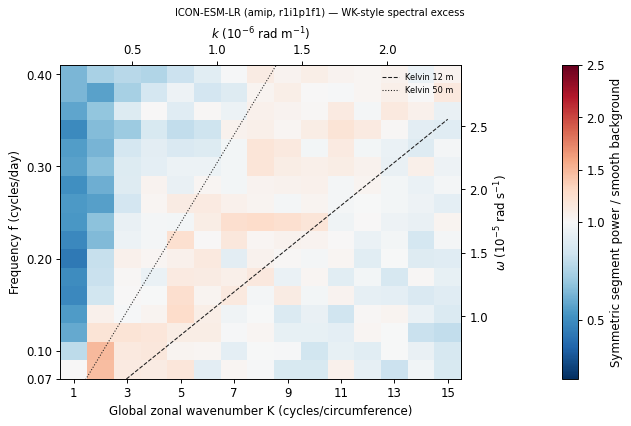

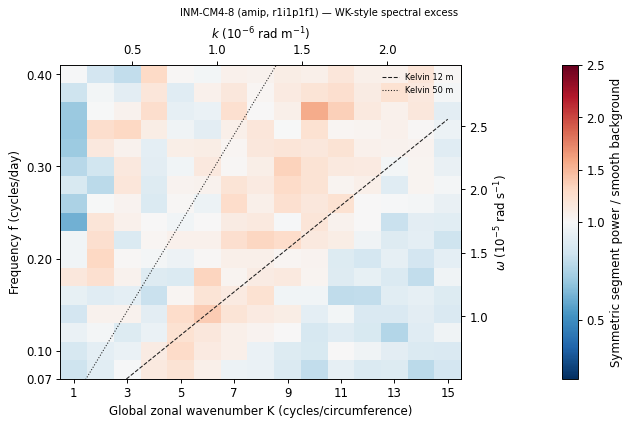

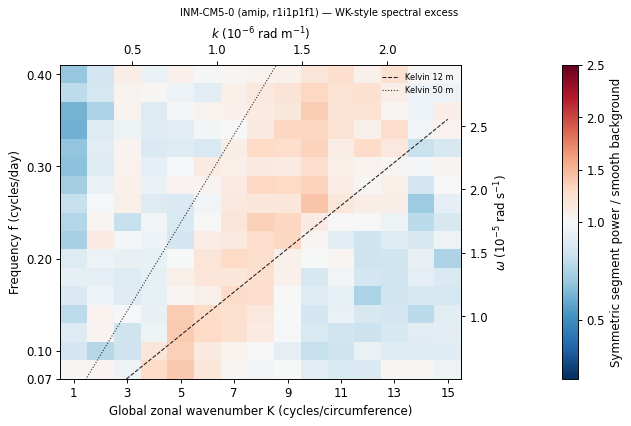

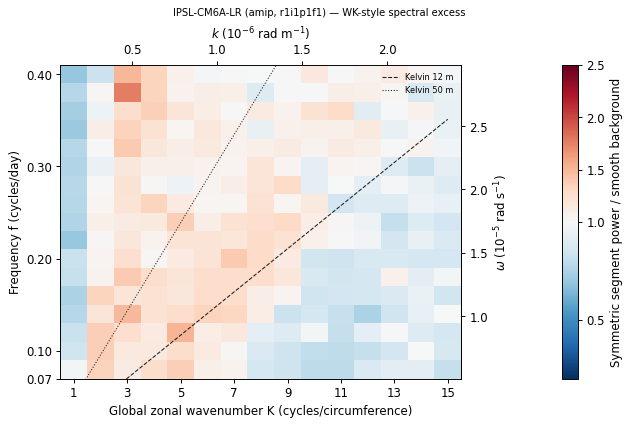

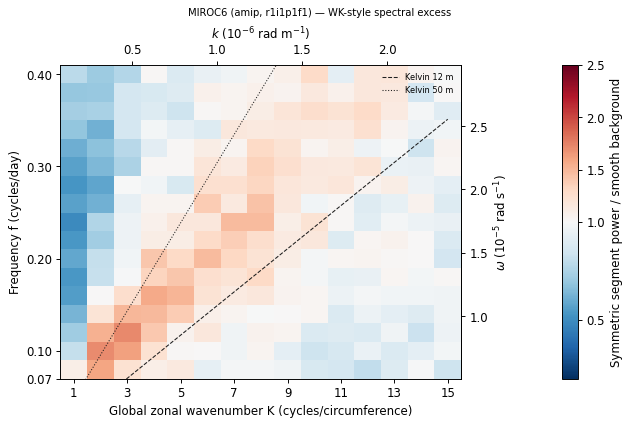

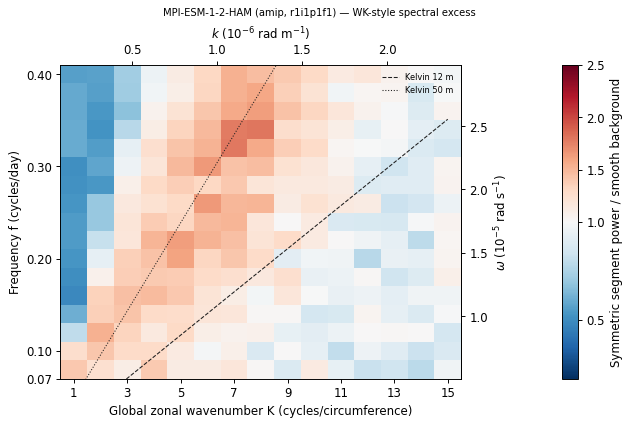

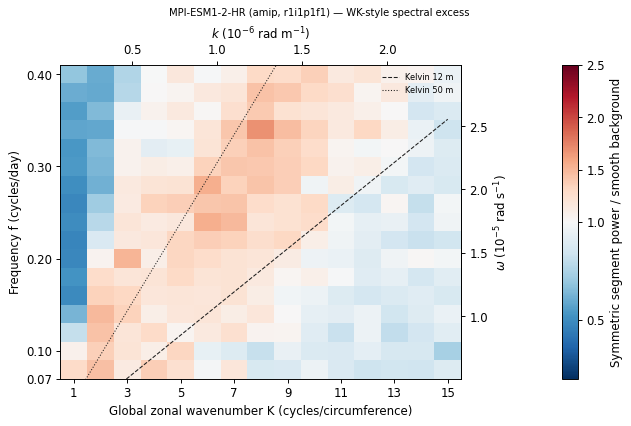

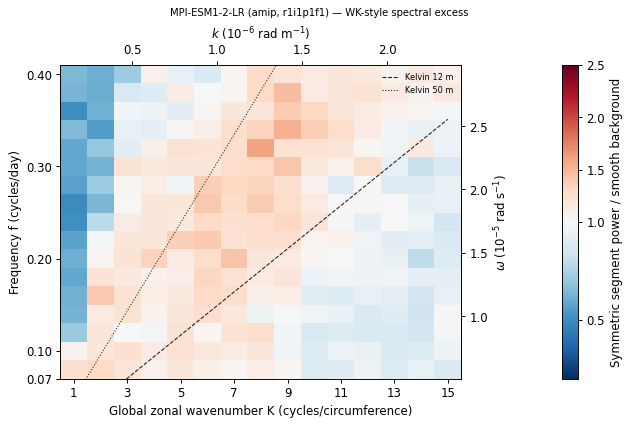

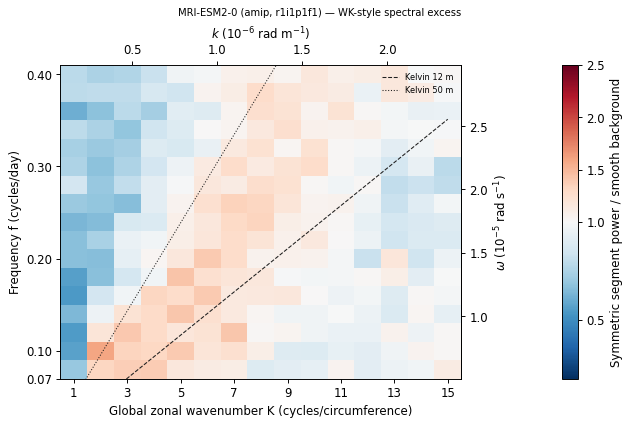

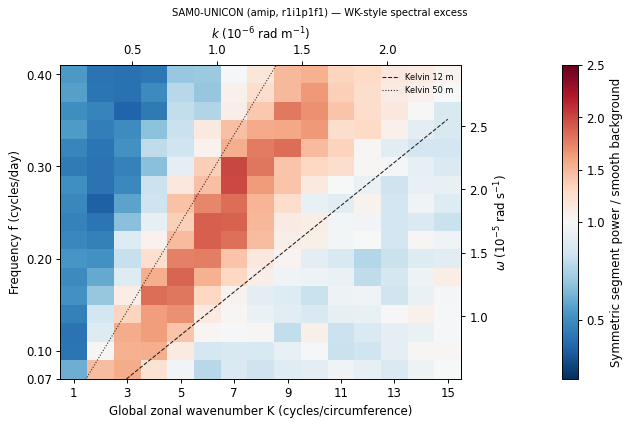

In [11]:
plot_records("excess", "amip")

## Integrated excess between the 12 and 50 m guide curves

This descriptive summary sums the **segment** OLR variance and smooth-background variance in cells whose bin-center $K,f$ imply a resting Kelvin depth from 12 to 50 m, then divides the sums. The result depends on these bin centers and the background estimate; it is not an event-fit depth statistic or a formal significance test.

In [12]:
K_center = (wk.K_left + wk.K_right) / 2
f_center = (wk.f_lower_cpd + wk.f_upper_cpd) / 2
kelvin_depth_m = ((2 * np.pi * f_center / 86400) / (K_center / EARTH_RADIUS_M))**2 / GRAVITY_M_S2
band = wk.loc[(kelvin_depth_m >= 12) & (kelvin_depth_m < 50)]
record_band = (band.groupby(IDENTITY)[["segment_variance_W2_m4", "smooth_background_variance_W2_m4"]]
               .sum().reset_index())
record_band["observed_to_background"] = (record_band.segment_variance_W2_m4
                                          / record_band.smooth_background_variance_W2_m4)
summary = []
for experiment in ("observations", "historical", "amip"):
    values = record_band.loc[record_band.experiment.eq(experiment), "observed_to_background"]
    summary.append(dict(experiment=experiment, records=len(values),
                        median_ratio=values.median(), minimum=values.min(), maximum=values.max()))
display(pd.DataFrame(summary).round(3))

,experiment,records,median_ratio,minimum,maximum
0,observations,1,1.612,1.612,1.612
1,historical,34,1.355,1.010,1.676
2,amip,25,1.269,1.043,1.522


## Interpretation limits

Event-footprint variance and segment Fourier variance have different denominators and assign variance to $K,f$ differently; their maps need not match. The event map is restricted to detected, quality-screened active components and includes background energy on those pixels. The segment map includes all OLR variance. The ratio map removes an estimated red background and is the appropriate place to look for a Wheeler–Kiladis-style ridge. The 12–50 m curves assume a resting Kelvin dispersion relation and are guides, not fitted modes. This project's daily OLR, projection, segmenting, background smoothing, and Kelvin filter box differ from the original Wheeler–Kiladis analysis. The ratio has not been assigned a binwise or global significance level here.

The NOAA WK-style map has a Kelvin-shaped excess ridge between the reference curves, whereas the raw variance map is dominated by the broad red background. The guide-band ratio table quantifies this visual comparison without assigning significance to individual bins.
